# Confirmatory hypothesis analysis: H1, H2, and H3

This notebook contains the prespecified book-level confirmatory analyses. It loads the finalized `book_summary_analysis.csv` table and gives every eligible book equal weight. No passages are resampled.

- **H1:** Domestic versus non-domestic fiction.
- **H2:** Female- versus male-protagonist represented interiority and historical change in that gap.
- **H3:** Historical change in quoted versus non-quoted interiority within domestic fiction.

Author gender is reported after the three primary hypotheses as a secondary extension of H2. All confidence intervals are 95% percentile intervals from 5,000 fixed-seed book-bootstrap iterations.


In [1]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/interiority_mplconfig")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from analysis_utils import (
    BOOTSTRAP_REPETITIONS,
    BOOTSTRAP_SEED,
    DOMESTIC_ORANGE,
    NONDOMESTIC_BLUE,
    PERIOD_COLORS,
    PUBLICATION_PERIODS,
    TIME_PERIOD_ORDER,
    configure_analysis_style,
    save_figure,
)

ROOT = Path.cwd()
ANALYSIS_TABLE_PATH = ROOT / "book_summary_analysis.csv"
OUTPUT_DIR = ROOT / "confirmatory_hypothesis_analysis_outputs"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

PERIOD_LABELS = dict(zip(TIME_PERIOD_ORDER, PUBLICATION_PERIODS))
SCOPE_BY_PERIOD = {
    "<1840": "primary",
    "1840-1899": "primary",
    "1900+": "extension",
}

configure_analysis_style()
print(f"Bootstrap iterations: {BOOTSTRAP_REPETITIONS:,}")
print(f"Fixed random seed: {BOOTSTRAP_SEED}")

Bootstrap iterations: 5,000
Fixed random seed: 20260731


## 1. Load and validate the finalized book-level data

The checks below enforce the unit of analysis and the prespecified variables. The notebook does not reconstruct either hypothesis metric from passage-level data.

In [2]:
book_data = pd.read_csv(ANALYSIS_TABLE_PATH, low_memory=False)

required_columns = {
    "gutenberg_id",
    "time_period",
    "is_domestic",
    "avg_interiority_score",
    "narrative_mode",
    "protagonist_analysis_status",
    "protagonist_gender",
    "author_gender",
    "narration_quotation_interiority_gap",
}
missing_columns = sorted(required_columns.difference(book_data.columns))
if missing_columns:
    raise KeyError(f"Finalized analysis table is missing: {missing_columns}")
if book_data["gutenberg_id"].duplicated().any():
    raise ValueError("Confirmatory analyses require exactly one row per book.")

book_data["is_domestic"] = pd.to_numeric(
    book_data["is_domestic"], errors="raise"
).astype(int)
if not set(book_data["is_domestic"].unique()).issubset({0, 1}):
    raise ValueError("is_domestic must be binary (0/1).")

observed_periods = set(book_data["time_period"].dropna().unique())
unexpected_periods = observed_periods.difference(TIME_PERIOD_ORDER)
if unexpected_periods:
    raise ValueError(f"Unexpected time_period values: {sorted(unexpected_periods)}")

for metric in ["avg_interiority_score", "narration_quotation_interiority_gap"]:
    book_data[metric] = pd.to_numeric(book_data[metric], errors="coerce")

validation_summary = pd.DataFrame(
    {
        "check": [
            "Rows",
            "Distinct Gutenberg IDs",
            "Valid H1 metric",
            "Domestic books",
            "Domestic books with valid H2 metric",
        ],
        "value": [
            len(book_data),
            book_data["gutenberg_id"].nunique(),
            book_data["avg_interiority_score"].notna().sum(),
            book_data["is_domestic"].eq(1).sum(),
            (
                book_data["is_domestic"].eq(1)
                & book_data["narration_quotation_interiority_gap"].notna()
            ).sum(),
        ],
    }
)
display(validation_summary)

,check,value
0,Rows,1348
1,Distinct Gutenberg IDs,1348
2,Valid H1 metric,1348
3,Domestic books,467
4,Domestic books with valid H2 metric,446


### Bootstrap design and shared helpers

The shared project constants and plotting style are used above. These local helpers retain the bootstrap draws because the historical contrasts must subtract period estimates generated within the same iteration. Each required period × group cell is independently resampled at its observed book count.

In [3]:
def bootstrap_mean_draws(values, rng, chunk_size=500):
    """Return fixed-size book-bootstrap mean draws without passage weighting."""
    scores = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy(float)
    if len(scores) == 0:
        raise ValueError("A prespecified bootstrap cell contains no valid books.")
    draws = np.empty(BOOTSTRAP_REPETITIONS, dtype=float)
    for start in range(0, BOOTSTRAP_REPETITIONS, chunk_size):
        stop = min(start + chunk_size, BOOTSTRAP_REPETITIONS)
        indices = rng.integers(0, len(scores), size=(stop - start, len(scores)))
        draws[start:stop] = scores[indices].mean(axis=1)
    return draws


def percentile_interval(draws):
    lower, upper = np.quantile(np.asarray(draws, dtype=float), [0.025, 0.975])
    return float(lower), float(upper)


def interval_position(lower, upper):
    if lower > 0:
        return "entirely above zero"
    if upper < 0:
        return "entirely below zero"
    return "spans zero"


def forest_plot(effect_table, labels, title, xlabel, stem):
    plot_data = effect_table.reset_index(drop=True).copy()
    y = np.arange(len(plot_data))
    colors = ["#374A5E" if scope == "primary" else "#8FA3B5" for scope in plot_data["interpretation_scope"]]
    fig, ax = plt.subplots(figsize=(9.2, max(3.4, 0.7 * len(plot_data) + 1.5)))
    for index, row in plot_data.iterrows():
        ax.errorbar(
            row["estimate"], y[index],
            xerr=[[row["estimate"] - row["ci_lower"]], [row["ci_upper"] - row["estimate"]]],
            fmt="o", color=colors[index], ecolor=colors[index],
            capsize=3, markersize=7, linewidth=2,
        )
    extent = np.nanmax(np.abs(plot_data[["ci_lower", "ci_upper"]].to_numpy()))
    extent = max(extent * 1.15, 0.05)
    ax.set_xlim(-extent, extent)
    ax.axvline(0, color="#333333", linewidth=1, linestyle="--")
    ax.set_yticks(y, labels=labels)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    save_figure(fig, FIGURE_DIR, stem)
    plt.show()

## H1 — Domestic versus non-domestic fiction

For each period, the confirmatory effect is the equal-book mean interiority of domestic books minus the equal-book mean of non-domestic books. The primary historical change is the 1840–1899 gap minus the Pre-1840 gap; the 1900+ minus 1840–1899 change is the extension.


In [4]:
h1_data = book_data.dropna(
    subset=["gutenberg_id", "time_period", "is_domestic", "avg_interiority_score"]
).copy()

h1_group_summary = (
    h1_data.assign(
        period=h1_data["time_period"].map(PERIOD_LABELS),
        domestic_status=h1_data["is_domestic"].map({1: "Domestic", 0: "Non-domestic"}),
    )
    .groupby(["time_period", "period", "is_domestic", "domestic_status"], observed=True, as_index=False)
    .agg(n_books=("gutenberg_id", "nunique"), mean_interiority=("avg_interiority_score", "mean"))
)
h1_group_summary["time_period"] = pd.Categorical(
    h1_group_summary["time_period"], categories=TIME_PERIOD_ORDER, ordered=True
)
h1_group_summary = h1_group_summary.sort_values(
    ["time_period", "is_domestic"], ascending=[True, False]
).reset_index(drop=True)

seed_sequence = np.random.SeedSequence(BOOTSTRAP_SEED)
h1_seed, h3_quote_seed, h2_gender_seed = seed_sequence.spawn(3)
h1_rng = np.random.default_rng(h1_seed)

h1_cell_values = {}
h1_cell_draws = {}
for period in TIME_PERIOD_ORDER:
    for domestic_status in [0, 1]:
        values = h1_data.loc[
            h1_data["time_period"].eq(period)
            & h1_data["is_domestic"].eq(domestic_status),
            "avg_interiority_score",
        ].to_numpy(float)
        h1_cell_values[(period, domestic_status)] = values
        h1_cell_draws[(period, domestic_status)] = bootstrap_mean_draws(values, h1_rng)

h1_gap_draws = {
    period: h1_cell_draws[(period, 1)] - h1_cell_draws[(period, 0)]
    for period in TIME_PERIOD_ORDER
}
h1_gap_estimates = {
    period: h1_cell_values[(period, 1)].mean() - h1_cell_values[(period, 0)].mean()
    for period in TIME_PERIOD_ORDER
}

h1_change_specs = [
    ("<1840", "1840-1899", "1840–1899 gap − Pre-1840 gap", "primary"),
    ("1840-1899", "1900+", "1900+ gap − 1840–1899 gap", "extension"),
]

h1_effect_rows = []
for period in TIME_PERIOD_ORDER:
    lower, upper = percentile_interval(h1_gap_draws[period])
    n_domestic = len(h1_cell_values[(period, 1)])
    n_non_domestic = len(h1_cell_values[(period, 0)])
    h1_effect_rows.append(
        {
            "hypothesis": "H1",
            "estimate_type": "direct_contrast",
            "period_or_contrast": f"{PERIOD_LABELS[period]}: domestic − non-domestic",
            "group": "Domestic − non-domestic",
            "estimate": h1_gap_estimates[period],
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": n_domestic + n_non_domestic,
            "n_domestic": n_domestic,
            "n_non_domestic": n_non_domestic,
            "book_counts": f"domestic={n_domestic}; non-domestic={n_non_domestic}",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        }
    )

for earlier, later, label, scope in h1_change_specs:
    change_draws = h1_gap_draws[later] - h1_gap_draws[earlier]
    lower, upper = percentile_interval(change_draws)
    n_domestic = len(h1_cell_values[(earlier, 1)]) + len(h1_cell_values[(later, 1)])
    n_non_domestic = len(h1_cell_values[(earlier, 0)]) + len(h1_cell_values[(later, 0)])
    h1_effect_rows.append(
        {
            "hypothesis": "H1",
            "estimate_type": "historical_change",
            "period_or_contrast": label,
            "group": "Change in domestic − non-domestic gap",
            "estimate": h1_gap_estimates[later] - h1_gap_estimates[earlier],
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": n_domestic + n_non_domestic,
            "n_domestic": n_domestic,
            "n_non_domestic": n_non_domestic,
            "book_counts": (
                f"{PERIOD_LABELS[earlier]}: D={len(h1_cell_values[(earlier, 1)])}, ND={len(h1_cell_values[(earlier, 0)])}; "
                f"{PERIOD_LABELS[later]}: D={len(h1_cell_values[(later, 1)])}, ND={len(h1_cell_values[(later, 0)])}"
            ),
            "interpretation_scope": scope,
        }
    )

h1_effects = pd.DataFrame(h1_effect_rows)

h1_period_mean_rows = []
for period in TIME_PERIOD_ORDER:
    for domestic_status in [1, 0]:
        lower, upper = percentile_interval(h1_cell_draws[(period, domestic_status)])
        values = h1_cell_values[(period, domestic_status)]
        h1_period_mean_rows.append(
            {
                "hypothesis": "H1",
                "estimate_type": "group_mean",
                "period_or_contrast": PERIOD_LABELS[period],
                "group": "Domestic" if domestic_status == 1 else "Non-domestic",
                "is_domestic": domestic_status,
                "estimate": values.mean(),
                "ci_lower": lower,
                "ci_upper": upper,
                "n_books": len(values),
                "n_domestic": len(values) if domestic_status == 1 else np.nan,
                "n_non_domestic": len(values) if domestic_status == 0 else np.nan,
                "book_counts": f"{'domestic' if domestic_status == 1 else 'non-domestic'}={len(values)}",
                "interpretation_scope": SCOPE_BY_PERIOD[period],
            }
        )
h1_period_means = pd.DataFrame(h1_period_mean_rows)
display(
    h1_period_means[
        ["period_or_contrast", "group", "n_books", "estimate", "ci_lower", "ci_upper"]
    ].round(4)
)


,period_or_contrast,group,n_books,estimate,ci_lower,ci_upper
0,Pre-1840,Domestic,19,1.3105,1.2068,1.3948
1,Pre-1840,Non-domestic,90,1.1283,1.0657,1.1894
2,1840–1899,Domestic,190,1.1728,1.1506,1.1952
3,1840–1899,Non-domestic,366,1.0120,0.9893,1.0336
4,1900+,Domestic,258,1.1950,1.1743,1.2158
5,1900+,Non-domestic,425,0.9981,0.9793,1.0170


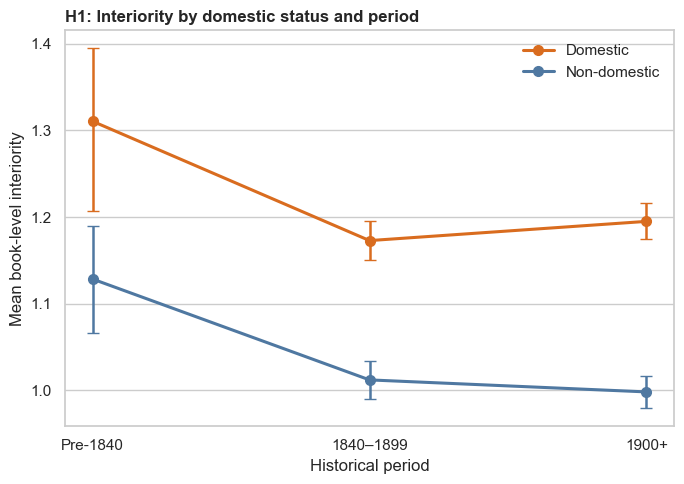

In [5]:
x = np.arange(len(TIME_PERIOD_ORDER))
fig, ax = plt.subplots(figsize=(7, 5))
for domestic_status, label, color in [
    (1, "Domestic", DOMESTIC_ORANGE),
    (0, "Non-domestic", NONDOMESTIC_BLUE),
]:
    rows = h1_period_means.loc[
        h1_period_means["is_domestic"].eq(domestic_status)
    ].reset_index(drop=True)
    estimates = rows["estimate"].to_numpy(float)
    ax.plot(x, estimates, marker="o", linewidth=2.2, markersize=7, color=color, label=label, zorder=3)
    ax.errorbar(
        x,
        estimates,
        yerr=np.vstack([estimates - rows["ci_lower"], rows["ci_upper"] - estimates]),
        fmt="none",
        ecolor=color,
        elinewidth=1.8,
        capsize=4,
        zorder=2,
    )
ax.set_xticks(x, PUBLICATION_PERIODS)
ax.set_xlabel("Historical period")
ax.set_ylabel("Mean book-level interiority")
ax.set_title("H1: Interiority by domestic status and period", loc="left", fontweight="bold")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
save_figure(fig, FIGURE_DIR, "h1_domestic_non_domestic_period_means")
plt.show()


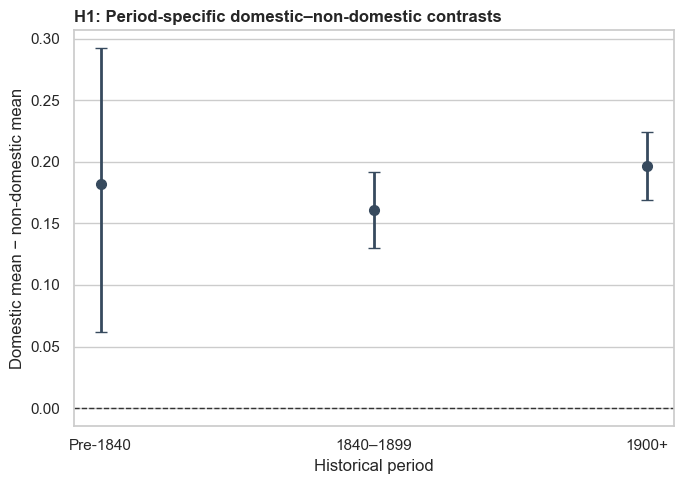

In [6]:
h1_direct_effects = h1_effects.loc[h1_effects["estimate_type"].eq("direct_contrast")].reset_index(drop=True)
x = np.arange(len(h1_direct_effects))
estimates = h1_direct_effects["estimate"].to_numpy(float)
fig, ax = plt.subplots(figsize=(7, 5.0))
ax.errorbar(
    x,
    estimates,
    yerr=np.vstack([
        estimates - h1_direct_effects["ci_lower"].to_numpy(float),
        h1_direct_effects["ci_upper"].to_numpy(float) - estimates,
    ]),
    fmt="o",
    color="#374A5E",
    ecolor="#374A5E",
    linewidth=2,
    capsize=4,
    markersize=7,
)
ax.axhline(0, color="#333333", linewidth=1, linestyle="--")
ax.set_xticks(x, PUBLICATION_PERIODS)
ax.set_xlabel("Historical period")
ax.set_ylabel("Domestic mean − non-domestic mean")
ax.set_title("H1: Period-specific domestic–non-domestic contrasts", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
fig.tight_layout()
save_figure(fig, FIGURE_DIR, "h1_domestic_non_domestic_direct_contrasts")
plt.show()


In [7]:
display(
    h1_effects[
        ["estimate_type", "period_or_contrast", "estimate", "ci_lower", "ci_upper", "book_counts", "interpretation_scope"]
    ].round(4)
)


,estimate_type,period_or_contrast,estimate,ci_lower,ci_upper,book_counts,interpretation_scope
0,direct_contrast,Pre-1840: domestic − non-domestic,0.1822,0.0621,0.2920,domestic=19; non-domestic=90,primary
1,direct_contrast,1840–1899: domestic − non-domestic,0.1609,0.1300,0.1915,domestic=190; non-domestic=366,primary
2,direct_contrast,1900+: domestic − non-domestic,0.1969,0.1691,0.2243,domestic=258; non-domestic=425,extension
3,historical_change,1840–1899 gap − Pre-1840 gap,-0.0213,-0.1334,0.0981,"Pre-1840: D=19, ND=90; 1840–1899: D=190, ND=366",primary
4,historical_change,1900+ gap − 1840–1899 gap,0.0360,-0.0052,0.0763,"1840–1899: D=190, ND=366; 1900+: D=258, ND=425",extension


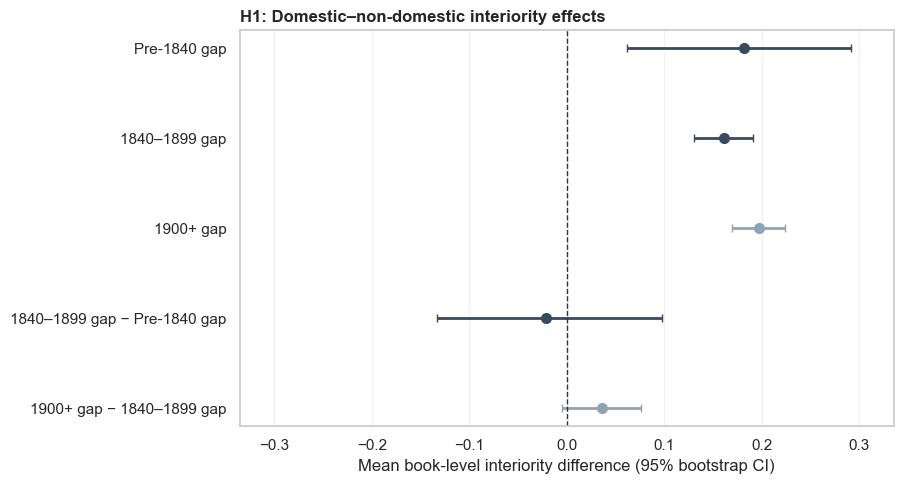

In [8]:
h1_forest_labels = [
    "Pre-1840 gap",
    "1840–1899 gap",
    "1900+ gap",
    "1840–1899 gap − Pre-1840 gap",
    "1900+ gap − 1840–1899 gap",
]
forest_plot(
    h1_effects,
    h1_forest_labels,
    "H1: Domestic–non-domestic interiority effects",
    "Mean book-level interiority difference (95% bootstrap CI)",
    "h1_domestic_non_domestic_forest",
)

In [9]:
h1_period_text = []
for _, row in h1_effects.loc[h1_effects["estimate_type"].eq("direct_contrast")].iterrows():
    direction = "higher" if row["estimate"] > 0 else "lower"
    consistency = "consistent" if row["estimate"] > 0 else "not consistent"
    h1_period_text.append(
        f"{row['period_or_contrast'].split(':')[0]}: domestic books were {direction} by {abs(row['estimate']):.3f} "
        f"points (95% CI {row['ci_lower']:.3f} to {row['ci_upper']:.3f}; {interval_position(row['ci_lower'], row['ci_upper'])}), "
        f"so the point estimate is {consistency} with H1."
    )
main_h1 = h1_effects.loc[
    h1_effects["period_or_contrast"].eq("1840–1899 gap − Pre-1840 gap")
].iloc[0]
extension_h1 = h1_effects.loc[
    h1_effects["period_or_contrast"].eq("1900+ gap − 1840–1899 gap")
].iloc[0]
display(Markdown(
    "### H1 factual summary\n\n"
    + " \n\n".join(h1_period_text)
    + f" The primary historical change was {main_h1['estimate']:.3f} "
      f"(95% CI {main_h1['ci_lower']:.3f} to {main_h1['ci_upper']:.3f}; {interval_position(main_h1['ci_lower'], main_h1['ci_upper'])})."
    + f" The twentieth-century extension was {extension_h1['estimate']:.3f} "
      f"(95% CI {extension_h1['ci_lower']:.3f} to {extension_h1['ci_upper']:.3f}; {interval_position(extension_h1['ci_lower'], extension_h1['ci_upper'])})."
))

### H1 factual summary

Pre-1840: domestic books were higher by 0.182 points (95% CI 0.062 to 0.292; entirely above zero), so the point estimate is consistent with H1. 

1840–1899: domestic books were higher by 0.161 points (95% CI 0.130 to 0.191; entirely above zero), so the point estimate is consistent with H1. 

1900+: domestic books were higher by 0.197 points (95% CI 0.169 to 0.224; entirely above zero), so the point estimate is consistent with H1. The primary historical change was -0.021 (95% CI -0.133 to 0.098; spans zero). The twentieth-century extension was 0.036 (95% CI -0.005 to 0.076; spans zero).

## H2 — Protagonist gender

All H2 descriptive and confirmatory outputs are restricted to books with `protagonist_analysis_status == "included"`. The primary contrast is the equal-book mean interiority of female-protagonist books minus that of male-protagonist books within period. Missing, ambiguous, `they`, and Mixed classifications do not enter the effects; Mixed remains available only in the descriptive count table.

The unadjusted contrast is primary. A parallel adjusted analysis standardizes female- and male-protagonist means in every period to the fixed 65.6% non-domestic / 34.4% domestic composition calculated from all books eligible for the author-gender extension. Both analyses use book-level resampling and calculate historical changes within bootstrap iteration.


In [10]:
# One common domestic/non-domestic target composition for adjusted H2 and author-extension results.
GENDER_STANDARDIZATION_REFERENCE = book_data.loc[
    book_data["time_period"].notna()
    & book_data["author_gender"].isin(["female", "male"])
    & book_data["is_domestic"].isin([0, 1])
    & book_data["avg_interiority_score"].notna(),
    ["gutenberg_id", "is_domestic"],
].copy()
GENDER_STANDARDIZATION_REFERENCE["is_domestic"] = GENDER_STANDARDIZATION_REFERENCE["is_domestic"].astype(int)
GENDER_STANDARDIZATION_WEIGHTS = (
    GENDER_STANDARDIZATION_REFERENCE["is_domestic"].value_counts(normalize=True).reindex([0, 1])
)
if GENDER_STANDARDIZATION_WEIGHTS.isna().any():
    raise ValueError("Gender standardization requires both domestic-status strata.")

# H2: protagonist gender
PROTAGONIST_LEVELS = ["F", "M", "mixed"]
PROTAGONIST_LABELS = {"F": "Female", "M": "Male", "mixed": "Mixed"}
PROTAGONIST_COLORS = {"F": "#9C6F91", "M": "#5B8E67", "mixed": "#7B8794"}

h2_protagonist_data = book_data.loc[
    book_data["protagonist_analysis_status"].eq("included")
    & book_data["time_period"].notna()
    & book_data["protagonist_gender"].isin(PROTAGONIST_LEVELS)
    & book_data["avg_interiority_score"].notna(),
    ["gutenberg_id", "time_period", "is_domestic", "protagonist_analysis_status", "protagonist_gender", "avg_interiority_score"],
].copy()
if not h2_protagonist_data["protagonist_analysis_status"].eq("included").all():
    raise AssertionError("Every H2 book must have protagonist_analysis_status == 'included'.")
h2_protagonist_data["is_domestic"] = h2_protagonist_data["is_domestic"].astype(int)

h2_protagonist_summary = (
    h2_protagonist_data.assign(
        period=h2_protagonist_data["time_period"].map(PERIOD_LABELS),
        gender=h2_protagonist_data["protagonist_gender"].map(PROTAGONIST_LABELS),
    )
    .groupby(["time_period", "period", "protagonist_gender", "gender"], observed=True, as_index=False)
    .agg(n_books=("gutenberg_id", "nunique"), mean_interiority=("avg_interiority_score", "mean"))
)
h2_protagonist_summary["time_period"] = pd.Categorical(
    h2_protagonist_summary["time_period"], categories=TIME_PERIOD_ORDER, ordered=True
)
h2_protagonist_summary["protagonist_gender"] = pd.Categorical(
    h2_protagonist_summary["protagonist_gender"], categories=PROTAGONIST_LEVELS, ordered=True
)
h2_protagonist_summary = h2_protagonist_summary.sort_values(
    ["time_period", "protagonist_gender"]
).reset_index(drop=True)

h2_rng = np.random.default_rng(h2_gender_seed)
h2_protagonist_values = {}
h2_protagonist_draws = {}
for period in TIME_PERIOD_ORDER:
    for gender in PROTAGONIST_LEVELS:
        values = h2_protagonist_data.loc[
            h2_protagonist_data["time_period"].eq(period)
            & h2_protagonist_data["protagonist_gender"].eq(gender),
            "avg_interiority_score",
        ].to_numpy(float)
        h2_protagonist_values[(period, gender)] = values
        h2_protagonist_draws[(period, gender)] = bootstrap_mean_draws(values, h2_rng)

h2_protagonist_gap_draws = {
    period: h2_protagonist_draws[(period, "F")] - h2_protagonist_draws[(period, "M")]
    for period in TIME_PERIOD_ORDER
}
h2_protagonist_gap_estimates = {
    period: h2_protagonist_values[(period, "F")].mean() - h2_protagonist_values[(period, "M")].mean()
    for period in TIME_PERIOD_ORDER
}

h2_protagonist_effect_rows = []
for period in TIME_PERIOD_ORDER:
    lower, upper = percentile_interval(h2_protagonist_gap_draws[period])
    n_female = len(h2_protagonist_values[(period, "F")])
    n_male = len(h2_protagonist_values[(period, "M")])
    h2_protagonist_effect_rows.append(
        {
            "hypothesis": "H2", "analysis_component": "primary_protagonist",
            "estimate_type": "direct_contrast",
            "period_or_contrast": f"{PERIOD_LABELS[period]}: female − male protagonist",
            "group": "Female − male protagonist", "estimate": h2_protagonist_gap_estimates[period],
            "ci_lower": lower, "ci_upper": upper, "n_books": n_female + n_male,
            "n_female": n_female, "n_male": n_male, "n_mixed": np.nan,
            "book_counts": f"female={n_female}; male={n_male}",
            "adjustment": "None; within-period equal-book means",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        }
    )

for earlier, later, label, scope in [
    ("<1840", "1840-1899", "1840–1899 protagonist gap − Pre-1840 protagonist gap", "primary"),
    ("1840-1899", "1900+", "1900+ protagonist gap − 1840–1899 protagonist gap", "extension"),
]:
    change_draws = h2_protagonist_gap_draws[later] - h2_protagonist_gap_draws[earlier]
    lower, upper = percentile_interval(change_draws)
    n_female = len(h2_protagonist_values[(earlier, "F")]) + len(h2_protagonist_values[(later, "F")])
    n_male = len(h2_protagonist_values[(earlier, "M")]) + len(h2_protagonist_values[(later, "M")])
    h2_protagonist_effect_rows.append(
        {
            "hypothesis": "H2", "analysis_component": "primary_protagonist",
            "estimate_type": "historical_change", "period_or_contrast": label,
            "group": "Change in female − male protagonist gap",
            "estimate": h2_protagonist_gap_estimates[later] - h2_protagonist_gap_estimates[earlier],
            "ci_lower": lower, "ci_upper": upper, "n_books": n_female + n_male,
            "n_female": n_female, "n_male": n_male, "n_mixed": np.nan,
            "book_counts": (
                f"{PERIOD_LABELS[earlier]}: F={len(h2_protagonist_values[(earlier, 'F')])}, M={len(h2_protagonist_values[(earlier, 'M')])}; "
                f"{PERIOD_LABELS[later]}: F={len(h2_protagonist_values[(later, 'F')])}, M={len(h2_protagonist_values[(later, 'M')])}"
            ),
            "adjustment": "None; within-period equal-book means",
            "interpretation_scope": scope,
        }
    )
h2_protagonist_effects = pd.DataFrame(h2_protagonist_effect_rows)


# Additional H2 standardization using the same fixed pooled H3b genre composition.
h2_protagonist_adjusted_rng = np.random.default_rng(h2_gender_seed.spawn(1)[0])
h2_protagonist_adjusted_values = {}
h2_protagonist_adjusted_cell_draws = {}
h2_protagonist_adjusted_means = {}
h2_protagonist_adjusted_draws = {}
for period in TIME_PERIOD_ORDER:
    period_data = h2_protagonist_data.loc[h2_protagonist_data["time_period"].eq(period)]
    for gender in ["F", "M"]:
        adjusted_mean = 0.0
        adjusted_draws = np.zeros(BOOTSTRAP_REPETITIONS)
        for domestic_status in [0, 1]:
            values = period_data.loc[
                period_data["protagonist_gender"].eq(gender)
                & period_data["is_domestic"].eq(domestic_status),
                "avg_interiority_score",
            ].to_numpy(float)
            if len(values) == 0:
                raise ValueError(f"Empty adjusted protagonist-gender cell: {period}, {domestic_status}, {gender}")
            draws = bootstrap_mean_draws(values, h2_protagonist_adjusted_rng)
            h2_protagonist_adjusted_values[(period, domestic_status, gender)] = values
            h2_protagonist_adjusted_cell_draws[(period, domestic_status, gender)] = draws
            adjusted_mean += GENDER_STANDARDIZATION_WEIGHTS.loc[domestic_status] * values.mean()
            adjusted_draws += GENDER_STANDARDIZATION_WEIGHTS.loc[domestic_status] * draws
        h2_protagonist_adjusted_means[(period, gender)] = adjusted_mean
        h2_protagonist_adjusted_draws[(period, gender)] = adjusted_draws

h2_protagonist_adjusted_gap_estimates = {
    period: h2_protagonist_adjusted_means[(period, "F")] - h2_protagonist_adjusted_means[(period, "M")]
    for period in TIME_PERIOD_ORDER
}
h2_protagonist_adjusted_gap_draws = {
    period: h2_protagonist_adjusted_draws[(period, "F")] - h2_protagonist_adjusted_draws[(period, "M")]
    for period in TIME_PERIOD_ORDER
}
h2_protagonist_adjusted_effect_rows = []
for period in TIME_PERIOD_ORDER:
    lower, upper = percentile_interval(h2_protagonist_adjusted_gap_draws[period])
    n_female = sum(len(h2_protagonist_adjusted_values[(period, status, "F")]) for status in [0, 1])
    n_male = sum(len(h2_protagonist_adjusted_values[(period, status, "M")]) for status in [0, 1])
    h2_protagonist_adjusted_effect_rows.append(
        {
            "hypothesis": "H2", "analysis_component": "protagonist_domestic_standardized",
            "estimate_type": "direct_contrast",
            "period_or_contrast": f"{PERIOD_LABELS[period]}: adjusted female − male protagonist",
            "group": "Adjusted female − male protagonist",
            "estimate": h2_protagonist_adjusted_gap_estimates[period],
            "ci_lower": lower, "ci_upper": upper, "n_books": n_female + n_male,
            "n_female": n_female, "n_male": n_male, "n_mixed": np.nan,
            "book_counts": f"female={n_female}; male={n_male}",
            "adjustment": (
                f"Fixed pooled H3b mix: non-domestic={GENDER_STANDARDIZATION_WEIGHTS.loc[0]:.3f}; "
                f"domestic={GENDER_STANDARDIZATION_WEIGHTS.loc[1]:.3f}"
            ),
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        }
    )

for earlier, later, label, scope in [
    ("<1840", "1840-1899", "1840–1899 adjusted protagonist gap − Pre-1840 adjusted protagonist gap", "primary"),
    ("1840-1899", "1900+", "1900+ adjusted protagonist gap − 1840–1899 adjusted protagonist gap", "extension"),
]:
    change_draws = h2_protagonist_adjusted_gap_draws[later] - h2_protagonist_adjusted_gap_draws[earlier]
    lower, upper = percentile_interval(change_draws)
    n_female = sum(len(h2_protagonist_adjusted_values[(period, status, "F")]) for period in [earlier, later] for status in [0, 1])
    n_male = sum(len(h2_protagonist_adjusted_values[(period, status, "M")]) for period in [earlier, later] for status in [0, 1])
    h2_protagonist_adjusted_effect_rows.append(
        {
            "hypothesis": "H2", "analysis_component": "protagonist_domestic_standardized",
            "estimate_type": "historical_change", "period_or_contrast": label,
            "group": "Change in adjusted female − male protagonist gap",
            "estimate": h2_protagonist_adjusted_gap_estimates[later] - h2_protagonist_adjusted_gap_estimates[earlier],
            "ci_lower": lower, "ci_upper": upper, "n_books": n_female + n_male,
            "n_female": n_female, "n_male": n_male, "n_mixed": np.nan,
            "book_counts": f"{PERIOD_LABELS[earlier]} and {PERIOD_LABELS[later]}: female={n_female}; male={n_male}",
            "adjustment": "Fixed pooled H3b domestic-status composition across all periods",
            "interpretation_scope": scope,
        }
    )
h2_protagonist_adjusted_effects = pd.DataFrame(h2_protagonist_adjusted_effect_rows)


In [11]:
display(Markdown("#### Protagonist-gender counts and equal-book means"))
display(
    h2_protagonist_summary.loc[
        h2_protagonist_summary["protagonist_gender"].isin(["F", "M"]),
        ["period", "gender", "n_books", "mean_interiority"],
    ].round(4)
)
display(Markdown(
    "**Adjustment.** Female- and male-protagonist means in every period are also standardized to "
    f"{GENDER_STANDARDIZATION_WEIGHTS.loc[0]:.1%} non-domestic / "
    f"{GENDER_STANDARDIZATION_WEIGHTS.loc[1]:.1%} domestic."
))
display(Markdown("#### H2 protagonist-gender contrasts"))
h2_protagonist_all_effects = pd.concat(
    [h2_protagonist_effects, h2_protagonist_adjusted_effects], ignore_index=True
)
display(
    h2_protagonist_all_effects[
        ["analysis_component", "estimate_type", "period_or_contrast", "estimate", "ci_lower", "ci_upper", "book_counts", "interpretation_scope"]
    ].round(4)
)


#### Protagonist-gender counts and equal-book means

,period,gender,n_books,mean_interiority
0,Pre-1840,Female,30,1.3950
1,Pre-1840,Male,43,1.0377
3,1840–1899,Female,154,1.1476
4,1840–1899,Male,219,0.9862
6,1900+,Female,162,1.1582
7,1900+,Male,289,1.0148


**Adjustment.** Female- and male-protagonist means in every period are also standardized to 65.5% non-domestic / 34.5% domestic.

#### H2 protagonist-gender contrasts

,analysis_component,estimate_type,period_or_contrast,estimate,ci_lower,ci_upper,book_counts,interpretation_scope
0,primary_protagonist,direct_contrast,Pre-1840: female − male protagonist,0.3573,0.2676,0.4501,female=30; male=43,primary
1,primary_protagonist,direct_contrast,1840–1899: female − male protagonist,0.1615,0.1208,0.2009,female=154; male=219,primary
2,primary_protagonist,direct_contrast,1900+: female − male protagonist,0.1434,0.1066,0.1776,female=162; male=289,extension
3,primary_protagonist,historical_change,1840–1899 protagonist gap − Pre-1840 protagoni...,-0.1959,-0.2985,-0.0992,"Pre-1840: F=30, M=43; 1840–1899: F=154, M=219",primary
4,primary_protagonist,historical_change,1900+ protagonist gap − 1840–1899 protagonist gap,-0.0181,-0.0718,0.0338,"1840–1899: F=154, M=219; 1900+: F=162, M=289",extension
5,protagonist_domestic_standardized,direct_contrast,Pre-1840: adjusted female − male protagonist,0.4115,0.3226,0.4967,female=30; male=43,primary
6,protagonist_domestic_standardized,direct_contrast,1840–1899: adjusted female − male protagonist,0.1239,0.0831,0.1652,female=154; male=219,primary
7,protagonist_domestic_standardized,direct_contrast,1900+: adjusted female − male protagonist,0.0732,0.0375,0.1098,female=162; male=289,extension
8,protagonist_domestic_standardized,historical_change,1840–1899 adjusted protagonist gap − Pre-1840 ...,-0.2876,-0.3818,-0.1902,Pre-1840 and 1840–1899: female=184; male=262,primary
9,protagonist_domestic_standardized,historical_change,1900+ adjusted protagonist gap − 1840–1899 adj...,-0.0508,-0.1053,0.0041,1840–1899 and 1900+: female=316; male=508,extension


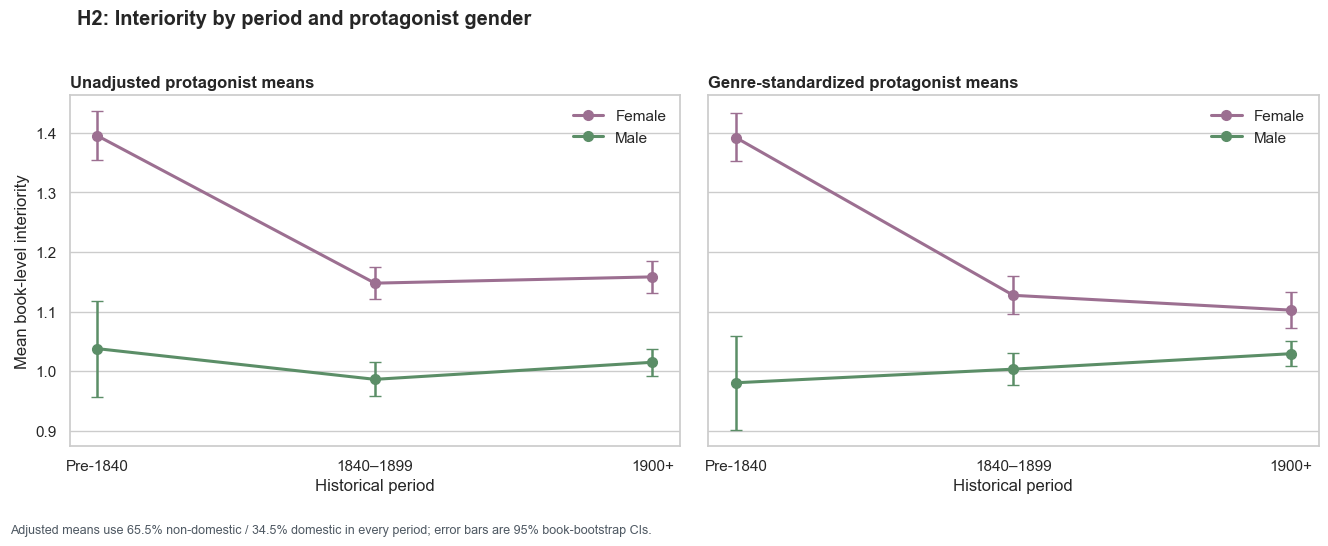

In [12]:
x = np.arange(len(TIME_PERIOD_ORDER))
fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.4), sharex=True, sharey=True)
for gender in ["F", "M"]:
    estimates = np.array([h2_protagonist_values[(period, gender)].mean() for period in TIME_PERIOD_ORDER])
    intervals = np.array([
        percentile_interval(h2_protagonist_draws[(period, gender)])
        for period in TIME_PERIOD_ORDER
    ])
    axes[0].plot(x, estimates, marker="o", linewidth=2.2, markersize=7, color=PROTAGONIST_COLORS[gender], label=PROTAGONIST_LABELS[gender], zorder=3)
    axes[0].errorbar(x, estimates, yerr=np.vstack([estimates - intervals[:, 0], intervals[:, 1] - estimates]), fmt="none", ecolor=PROTAGONIST_COLORS[gender], elinewidth=1.8, capsize=4, zorder=2)

    adjusted_estimates = np.array([h2_protagonist_adjusted_means[(period, gender)] for period in TIME_PERIOD_ORDER])
    adjusted_intervals = np.array([
        percentile_interval(h2_protagonist_adjusted_draws[(period, gender)])
        for period in TIME_PERIOD_ORDER
    ])
    axes[1].plot(x, adjusted_estimates, marker="o", linewidth=2.2, markersize=7, color=PROTAGONIST_COLORS[gender], label=PROTAGONIST_LABELS[gender], zorder=3)
    axes[1].errorbar(x, adjusted_estimates, yerr=np.vstack([adjusted_estimates - adjusted_intervals[:, 0], adjusted_intervals[:, 1] - adjusted_estimates]), fmt="none", ecolor=PROTAGONIST_COLORS[gender], elinewidth=1.8, capsize=4, zorder=2)

for ax, title in zip(axes, ["Unadjusted protagonist means", "Genre-standardized protagonist means"]):
    ax.set_xticks(x, PUBLICATION_PERIODS)
    ax.set_xlabel("Historical period")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.legend(frameon=False)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Mean book-level interiority")
fig.suptitle("H2: Interiority by period and protagonist gender", x=0.06, ha="left", fontweight="bold")
fig.text(0.01, 0.01, f"Adjusted means use {GENDER_STANDARDIZATION_WEIGHTS.loc[0]:.1%} non-domestic / {GENDER_STANDARDIZATION_WEIGHTS.loc[1]:.1%} domestic in every period; error bars are 95% book-bootstrap CIs.", fontsize=9, color="#4F5963")
fig.tight_layout(rect=[0, 0.05, 1, 0.96])
save_figure(fig, FIGURE_DIR, "h2_protagonist_gender_period_means")
plt.show()


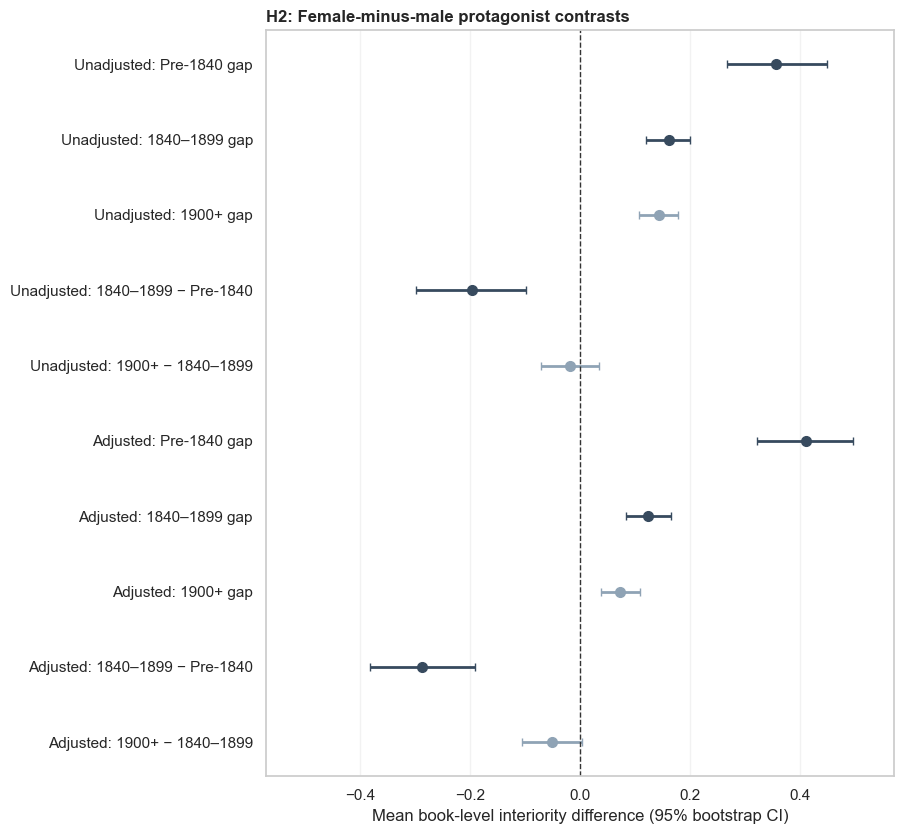

In [13]:
h2_forest_labels = [
    "Unadjusted: Pre-1840 gap", "Unadjusted: 1840–1899 gap", "Unadjusted: 1900+ gap",
    "Unadjusted: 1840–1899 − Pre-1840", "Unadjusted: 1900+ − 1840–1899",
    "Adjusted: Pre-1840 gap", "Adjusted: 1840–1899 gap", "Adjusted: 1900+ gap",
    "Adjusted: 1840–1899 − Pre-1840", "Adjusted: 1900+ − 1840–1899",
]
forest_plot(
    h2_protagonist_all_effects,
    h2_forest_labels,
    "H2: Female-minus-male protagonist contrasts",
    "Mean book-level interiority difference (95% bootstrap CI)",
    "h2_protagonist_gender_contrasts_forest",
)


In [14]:
h2_primary_change = h2_protagonist_effects.loc[
    h2_protagonist_effects["estimate_type"].eq("historical_change")
].iloc[0]
h2_primary_extension = h2_protagonist_effects.loc[
    h2_protagonist_effects["estimate_type"].eq("historical_change")
].iloc[1]
h2_adjusted_change = h2_protagonist_adjusted_effects.loc[
    h2_protagonist_adjusted_effects["estimate_type"].eq("historical_change")
].iloc[0]
display(Markdown(
    "### H2 factual summary\n\n"
    f"The primary unadjusted protagonist-gap change was {h2_primary_change['estimate']:.3f} "
    f"(95% CI {h2_primary_change['ci_lower']:.3f} to {h2_primary_change['ci_upper']:.3f}; "
    f"{interval_position(h2_primary_change['ci_lower'], h2_primary_change['ci_upper'])}). "
    f"The twentieth-century extension was {h2_primary_extension['estimate']:.3f} "
    f"(95% CI {h2_primary_extension['ci_lower']:.3f} to {h2_primary_extension['ci_upper']:.3f}). "
    f"Under the fixed genre composition, the primary adjusted change was {h2_adjusted_change['estimate']:.3f} "
    f"(95% CI {h2_adjusted_change['ci_lower']:.3f} to {h2_adjusted_change['ci_upper']:.3f})."
))


### H2 factual summary

The primary unadjusted protagonist-gap change was -0.196 (95% CI -0.298 to -0.099; entirely below zero). The twentieth-century extension was -0.018 (95% CI -0.072 to 0.034). Under the fixed genre composition, the primary adjusted change was -0.288 (95% CI -0.382 to -0.190).

## H3 — Quoted versus non-quoted interiority within domestic fiction

### Section A — All narrative modes

The primary analysis is restricted to domestic books and uses the finalized book-level `narration_quotation_interiority_gap` without redefining its component measures. Positive values indicate that represented interiority is more concentrated in narration than quotation. Period means are descriptive; the prespecified historical differences between those means are the direct hypothesis contrasts. The non-domestic panel is a descriptive companion that includes genre and non-genre books.


In [15]:
h3_quote_data = book_data.loc[
    book_data["is_domestic"].eq(1)
    & book_data["time_period"].notna()
    & book_data["narration_quotation_interiority_gap"].notna(),
    ["gutenberg_id", "time_period", "narration_quotation_interiority_gap"],
].copy()

h3_quote_rng = np.random.default_rng(h3_quote_seed)
h3_quote_period_values = {}
h3_quote_period_draws = {}
h3_quote_period_rows = []
for period in TIME_PERIOD_ORDER:
    values = h3_quote_data.loc[
        h3_quote_data["time_period"].eq(period),
        "narration_quotation_interiority_gap",
    ].to_numpy(float)
    draws = bootstrap_mean_draws(values, h3_quote_rng)
    lower, upper = percentile_interval(draws)
    h3_quote_period_values[period] = values
    h3_quote_period_draws[period] = draws
    h3_quote_period_rows.append(
        {
            "hypothesis": "H3",
            "estimate_type": "group_mean",
            "period_or_contrast": PERIOD_LABELS[period],
            "group": "Domestic books",
            "estimate": values.mean(),
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": len(values),
            "n_domestic": len(values),
            "n_non_domestic": np.nan,
            "book_counts": f"domestic={len(values)}",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        }
    )

h3_quote_period_means = pd.DataFrame(h3_quote_period_rows)
h3_quote_change_rows = []
for earlier, later, label, scope in [
    ("<1840", "1840-1899", "1840–1899 mean − Pre-1840 mean", "primary"),
    ("1840-1899", "1900+", "1900+ mean − 1840–1899 mean", "extension"),
]:
    change_draws = h3_quote_period_draws[later] - h3_quote_period_draws[earlier]
    lower, upper = percentile_interval(change_draws)
    earlier_n = len(h3_quote_period_values[earlier])
    later_n = len(h3_quote_period_values[later])
    h3_quote_change_rows.append(
        {
            "hypothesis": "H3",
            "estimate_type": "historical_change",
            "period_or_contrast": label,
            "group": "Domestic books",
            "estimate": h3_quote_period_values[later].mean() - h3_quote_period_values[earlier].mean(),
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": earlier_n + later_n,
            "n_domestic": earlier_n + later_n,
            "n_non_domestic": np.nan,
            "book_counts": f"{PERIOD_LABELS[earlier]}={earlier_n}; {PERIOD_LABELS[later]}={later_n}",
            "interpretation_scope": scope,
        }
    )

h3_quote_changes = pd.DataFrame(h3_quote_change_rows)
display(h3_quote_period_means[["period_or_contrast", "n_books", "estimate", "ci_lower", "ci_upper", "interpretation_scope"]].round(4))
display(h3_quote_changes[["period_or_contrast", "estimate", "ci_lower", "ci_upper", "book_counts", "interpretation_scope"]].round(4))


,period_or_contrast,n_books,estimate,ci_lower,ci_upper,interpretation_scope
0,Pre-1840,17,0.0357,-0.0971,0.1570,primary
1,1840–1899,187,0.2061,0.1714,0.2396,primary
2,1900+,242,0.2298,0.1966,0.2634,extension


,period_or_contrast,estimate,ci_lower,ci_upper,book_counts,interpretation_scope
0,1840–1899 mean − Pre-1840 mean,0.1704,0.0455,0.3106,Pre-1840=17; 1840–1899=187,primary
1,1900+ mean − 1840–1899 mean,0.0238,-0.0236,0.0718,1840–1899=187; 1900+=242,extension


In [16]:
# The domestic and non-domestic period-mean plots are rendered together below.


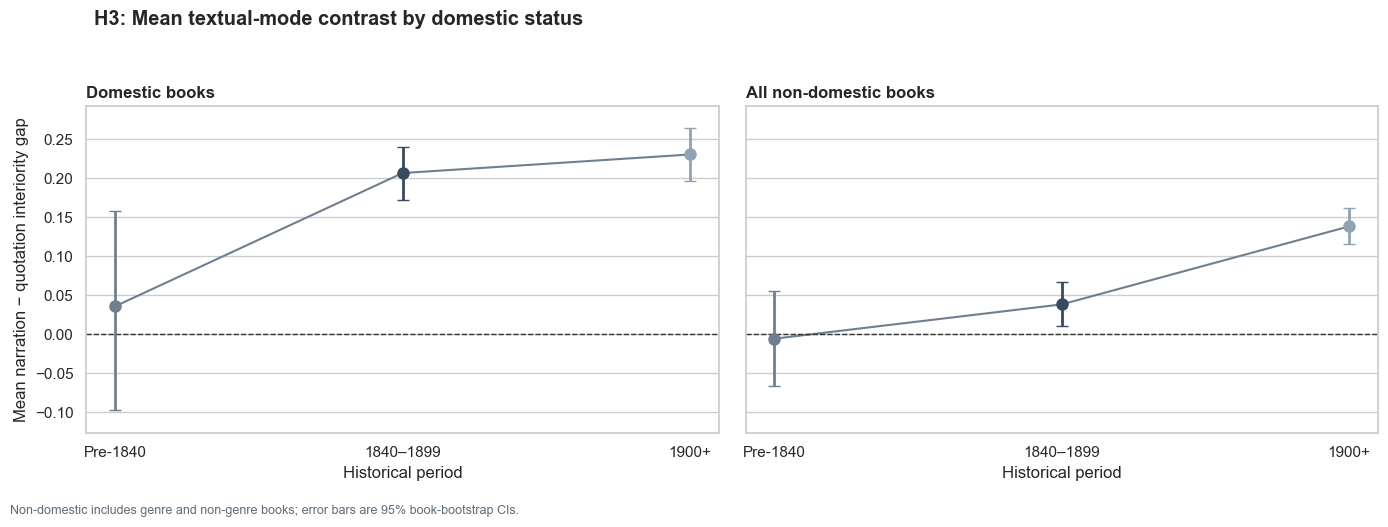

In [17]:
# Descriptive companion to H3: all non-domestic books, including both genre and non-genre fiction.
h3_quote_non_domestic_data = book_data.loc[
    book_data["is_domestic"].eq(0)
    & book_data["time_period"].notna()
    & book_data["narration_quotation_interiority_gap"].notna(),
    ["gutenberg_id", "time_period", "narration_quotation_interiority_gap"],
].copy()

h3_quote_non_domestic_rng = np.random.default_rng(
    np.random.SeedSequence([BOOTSTRAP_SEED, 303])
)
h3_quote_non_domestic_rows = []
for period in TIME_PERIOD_ORDER:
    values = h3_quote_non_domestic_data.loc[
        h3_quote_non_domestic_data["time_period"].eq(period),
        "narration_quotation_interiority_gap",
    ].to_numpy(float)
    draws = bootstrap_mean_draws(values, h3_quote_non_domestic_rng)
    lower, upper = percentile_interval(draws)
    h3_quote_non_domestic_rows.append(
        {
            "period": PERIOD_LABELS[period],
            "estimate": values.mean(),
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": len(values),
        }
    )

h3_quote_non_domestic_period_means = pd.DataFrame(h3_quote_non_domestic_rows)

x = np.arange(len(TIME_PERIOD_ORDER))
h3_period_plot_tables = [
    (h3_quote_period_means, "Domestic books"),
    (h3_quote_non_domestic_period_means, "All non-domestic books"),
]
h3_ci_bounds = pd.concat(
    [table[["ci_lower", "ci_upper"]] for table, _ in h3_period_plot_tables],
    ignore_index=True,
)
h3_y_min = min(0, h3_ci_bounds["ci_lower"].min())
h3_y_max = max(0, h3_ci_bounds["ci_upper"].max())
h3_y_padding = 0.08 * (h3_y_max - h3_y_min)
h3_common_ylim = (h3_y_min - h3_y_padding, h3_y_max + h3_y_padding)

def draw_h3_period_means(ax, table, panel_title):
    for index, period in enumerate(TIME_PERIOD_ORDER):
        row = table.iloc[index]
        color = PERIOD_COLORS[PERIOD_LABELS[period]]
        ax.errorbar(
            x[index], row["estimate"],
            yerr=[[row["estimate"] - row["ci_lower"]], [row["ci_upper"] - row["estimate"]]],
            fmt="o", color=color, ecolor=color, capsize=4, markersize=8, linewidth=2, zorder=3,
        )
    ax.plot(x, table["estimate"], color="#6F7F90", linewidth=1.5, zorder=1)
    ax.axhline(0, color="#333333", linewidth=1, linestyle="--")
    ax.set_xticks(x, PUBLICATION_PERIODS)
    ax.set_xlabel("Historical period")
    ax.set_title(panel_title, loc="left", fontweight="bold")
    ax.set_ylim(h3_common_ylim)
    ax.grid(axis="x", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.2), sharey=True)
for ax, (table, panel_title) in zip(axes, h3_period_plot_tables):
    draw_h3_period_means(ax, table, panel_title)
axes[0].set_ylabel("Mean narration − quotation interiority gap")
fig.suptitle("H3: Mean textual-mode contrast by domestic status", x=0.07, ha="left", fontweight="bold")
fig.text(
    0.01, 0.01,
    "Non-domestic includes genre and non-genre books; error bars are 95% book-bootstrap CIs.",
    fontsize=9, color="#5F6B76",
)
fig.tight_layout(rect=[0, 0.04, 1, 0.94])
save_figure(fig, FIGURE_DIR, "h3_quote_domestic_and_non_domestic_period_means")
plt.show()

# Keep the standalone exports synchronized to the same shared y-axis range.
for table, panel_title, stem in [
    (h3_quote_period_means, "H3: Mean textual-mode contrast in domestic books", "h3_quote_domestic_period_means"),
    (h3_quote_non_domestic_period_means, "H3 companion: Mean textual-mode contrast in all non-domestic books", "h3_quote_non_domestic_period_means"),
]:
    standalone_fig, standalone_ax = plt.subplots(figsize=(8.4, 5.0))
    draw_h3_period_means(standalone_ax, table, panel_title)
    standalone_ax.set_ylabel("Mean narration − quotation interiority gap")
    standalone_fig.tight_layout()
    save_figure(standalone_fig, FIGURE_DIR, stem)
    plt.close(standalone_fig)


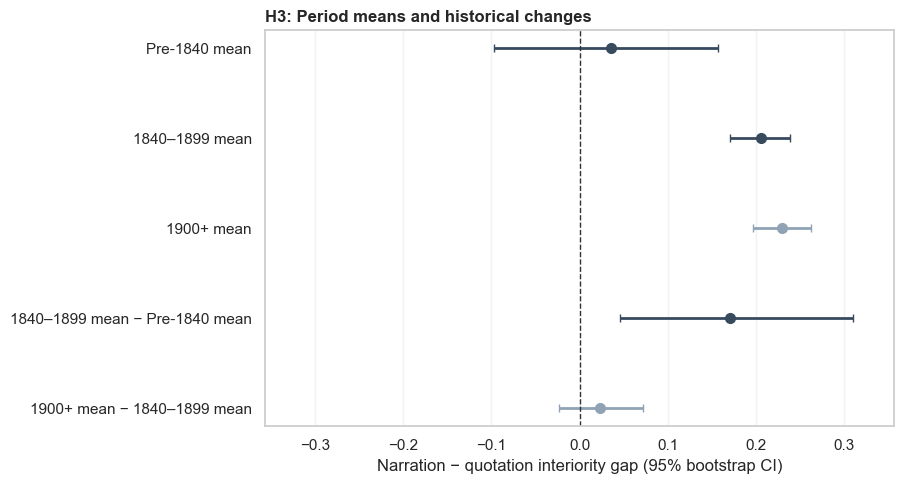

In [18]:
h3_quote_forest_data = pd.concat([h3_quote_period_means, h3_quote_changes], ignore_index=True)
h3_quote_forest_labels = [
    "Pre-1840 mean",
    "1840–1899 mean",
    "1900+ mean",
    "1840–1899 mean − Pre-1840 mean",
    "1900+ mean − 1840–1899 mean",
]
forest_plot(
    h3_quote_forest_data,
    h3_quote_forest_labels,
    "H3: Period means and historical changes",
    "Narration − quotation interiority gap (95% bootstrap CI)",
    "h3_quote_period_means_and_changes_forest",
)


In [19]:
h3_quote_mean_text = []
for _, row in h3_quote_period_means.iterrows():
    direction = "favored narration" if row["estimate"] > 0 else "favored quotation"
    h3_quote_mean_text.append(
        f"{row['period_or_contrast']}: the mean contrast was {row['estimate']:.3f} "
        f"(95% CI {row['ci_lower']:.3f} to {row['ci_upper']:.3f}; {interval_position(row['ci_lower'], row['ci_upper'])}), "
        f"and the point estimate {direction}."
    )
main_h3 = h3_quote_changes.iloc[0]
extension_h3 = h3_quote_changes.iloc[1]
main_consistency = "consistent" if main_h3["estimate"] > 0 else "not consistent"
extension_consistency = "consistent" if extension_h3["estimate"] > 0 else "not consistent"
display(Markdown(
    "### H3 factual summary\n\n"
    + " \n\n".join(h3_quote_mean_text)
    + f" The primary historical increase was {main_h3['estimate']:.3f} "
      f"(95% CI {main_h3['ci_lower']:.3f} to {main_h3['ci_upper']:.3f}; {interval_position(main_h3['ci_lower'], main_h3['ci_upper'])}); "
      f"its point estimate is {main_consistency} with H3."
    + f" The twentieth-century extension was {extension_h3['estimate']:.3f} "
      f"(95% CI {extension_h3['ci_lower']:.3f} to {extension_h3['ci_upper']:.3f}; {interval_position(extension_h3['ci_lower'], extension_h3['ci_upper'])}); "
      f"its point estimate is {extension_consistency} with a continued shift in the predicted direction."
))


### H3 factual summary

Pre-1840: the mean contrast was 0.036 (95% CI -0.097 to 0.157; spans zero), and the point estimate favored narration. 

1840–1899: the mean contrast was 0.206 (95% CI 0.171 to 0.240; entirely above zero), and the point estimate favored narration. 

1900+: the mean contrast was 0.230 (95% CI 0.197 to 0.263; entirely above zero), and the point estimate favored narration. The primary historical increase was 0.170 (95% CI 0.045 to 0.311; entirely above zero); its point estimate is consistent with H3. The twentieth-century extension was 0.024 (95% CI -0.024 to 0.072; spans zero); its point estimate is consistent with a continued shift in the predicted direction.

### Section B — Third-person narrative mode

This restricted analysis retains books whose finalized `narrative_mode` is `third_person_candidate` or `third_person`. It applies the same equal-book metric and 5,000-iteration book bootstrap as Section A, separately within each period and domestic-status group. The domestic analysis remains the H3-relevant restriction; the all-non-domestic analysis is a descriptive companion and includes both genre and non-genre books.


In [20]:
H3B_THIRD_PERSON_MODES = ["third_person_candidate", "third_person"]
h3b_narrative_mode = book_data["narrative_mode"].astype("string").str.strip().str.lower()
h3b_third_person_data = book_data.loc[
    h3b_narrative_mode.isin(H3B_THIRD_PERSON_MODES)
    & book_data["is_domestic"].isin([0, 1])
    & book_data["time_period"].notna()
    & book_data["narration_quotation_interiority_gap"].notna(),
    ["gutenberg_id", "time_period", "is_domestic", "narrative_mode", "narration_quotation_interiority_gap"],
].copy()
h3b_third_person_data["is_domestic"] = h3b_third_person_data["is_domestic"].astype(int)

h3b_group_labels = {1: "Domestic books", 0: "All non-domestic books"}
h3b_rng = np.random.default_rng(np.random.SeedSequence([BOOTSTRAP_SEED, 313]))
h3b_period_values = {}
h3b_period_draws = {}
h3b_period_rows = []
for domestic_status in [1, 0]:
    for period in TIME_PERIOD_ORDER:
        values = h3b_third_person_data.loc[
            h3b_third_person_data["is_domestic"].eq(domestic_status)
            & h3b_third_person_data["time_period"].eq(period),
            "narration_quotation_interiority_gap",
        ].to_numpy(float)
        draws = bootstrap_mean_draws(values, h3b_rng)
        lower, upper = percentile_interval(draws)
        h3b_period_values[(domestic_status, period)] = values
        h3b_period_draws[(domestic_status, period)] = draws
        h3b_period_rows.append({
            "hypothesis": "H3 Section B",
            "estimate_type": "group_mean",
            "period_or_contrast": PERIOD_LABELS[period],
            "group": h3b_group_labels[domestic_status],
            "estimate": values.mean(),
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": len(values),
            "n_domestic": len(values) if domestic_status == 1 else np.nan,
            "n_non_domestic": len(values) if domestic_status == 0 else np.nan,
            "book_counts": f"{h3b_group_labels[domestic_status].lower()}={len(values)}",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        })

h3b_third_person_period_means = pd.DataFrame(h3b_period_rows)
h3b_change_rows = []
for domestic_status in [1, 0]:
    for earlier, later, label, scope in [
        ("<1840", "1840-1899", "1840–1899 mean − Pre-1840 mean", "primary"),
        ("1840-1899", "1900+", "1900+ mean − 1840–1899 mean", "extension"),
    ]:
        change_draws = h3b_period_draws[(domestic_status, later)] - h3b_period_draws[(domestic_status, earlier)]
        lower, upper = percentile_interval(change_draws)
        earlier_values = h3b_period_values[(domestic_status, earlier)]
        later_values = h3b_period_values[(domestic_status, later)]
        h3b_change_rows.append({
            "hypothesis": "H3 Section B",
            "estimate_type": "historical_change",
            "period_or_contrast": label,
            "group": h3b_group_labels[domestic_status],
            "estimate": later_values.mean() - earlier_values.mean(),
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": len(earlier_values) + len(later_values),
            "n_domestic": len(earlier_values) + len(later_values) if domestic_status == 1 else np.nan,
            "n_non_domestic": len(earlier_values) + len(later_values) if domestic_status == 0 else np.nan,
            "book_counts": f"{PERIOD_LABELS[earlier]}={len(earlier_values)}; {PERIOD_LABELS[later]}={len(later_values)}",
            "interpretation_scope": scope,
        })

h3b_third_person_changes = pd.DataFrame(h3b_change_rows)
h3b_third_person_period_means.to_csv(TABLE_DIR / "h3b_third_person_period_means.csv", index=False)
h3b_third_person_changes.to_csv(TABLE_DIR / "h3b_third_person_historical_changes.csv", index=False)

display(Markdown("#### Third-person book counts and period means"))
display(h3b_third_person_period_means[["group", "period_or_contrast", "n_books", "estimate", "ci_lower", "ci_upper"]].round(4))
display(Markdown("#### Third-person historical changes"))
display(h3b_third_person_changes[["group", "period_or_contrast", "estimate", "ci_lower", "ci_upper", "book_counts"]].round(4))

# Direct third-person domestic-minus-non-domestic contrast within each period.
h3b_domestic_non_domestic_rows = []
for period in TIME_PERIOD_ORDER:
    domestic_values = h3b_period_values[(1, period)]
    non_domestic_values = h3b_period_values[(0, period)]
    contrast_draws = h3b_period_draws[(1, period)] - h3b_period_draws[(0, period)]
    lower, upper = percentile_interval(contrast_draws)
    h3b_domestic_non_domestic_rows.append({
        "hypothesis": "H3 Section B",
        "estimate_type": "direct_contrast",
        "period_or_contrast": f"{PERIOD_LABELS[period]}: domestic − non-domestic",
        "group": "Domestic − non-domestic",
        "estimate": domestic_values.mean() - non_domestic_values.mean(),
        "ci_lower": lower,
        "ci_upper": upper,
        "n_books": len(domestic_values) + len(non_domestic_values),
        "n_domestic": len(domestic_values),
        "n_non_domestic": len(non_domestic_values),
        "book_counts": f"domestic={len(domestic_values)}; non-domestic={len(non_domestic_values)}",
        "interpretation_scope": SCOPE_BY_PERIOD[period],
    })

h3b_third_person_domestic_non_domestic_contrasts = pd.DataFrame(h3b_domestic_non_domestic_rows)
h3b_third_person_domestic_non_domestic_contrasts.to_csv(
    TABLE_DIR / "h3b_third_person_domestic_minus_non_domestic_contrasts.csv", index=False
)
display(Markdown("#### Third-person domestic − non-domestic contrast by period"))
display(h3b_third_person_domestic_non_domestic_contrasts[[
    "period_or_contrast", "n_domestic", "n_non_domestic", "estimate", "ci_lower", "ci_upper", "interpretation_scope"
]].round(4))


#### Third-person book counts and period means

,group,period_or_contrast,n_books,estimate,ci_lower,ci_upper
0,Domestic books,Pre-1840,13,0.0251,-0.1212,0.1571
1,Domestic books,1840–1899,152,0.2089,0.1714,0.2475
2,Domestic books,1900+,207,0.2248,0.1878,0.2615
3,All non-domestic books,Pre-1840,50,-0.0276,-0.0965,0.0399
4,All non-domestic books,1840–1899,237,-0.0003,-0.0337,0.0331
5,All non-domestic books,1900+,270,0.1260,0.0961,0.1560


#### Third-person historical changes

,group,period_or_contrast,estimate,ci_lower,ci_upper,book_counts
0,Domestic books,1840–1899 mean − Pre-1840 mean,0.1839,0.0455,0.3326,Pre-1840=13; 1840–1899=152
1,Domestic books,1900+ mean − 1840–1899 mean,0.0159,-0.0358,0.0687,1840–1899=152; 1900+=207
2,All non-domestic books,1840–1899 mean − Pre-1840 mean,0.0272,-0.0459,0.1032,Pre-1840=50; 1840–1899=237
3,All non-domestic books,1900+ mean − 1840–1899 mean,0.1264,0.0821,0.1699,1840–1899=237; 1900+=270


#### Third-person domestic − non-domestic contrast by period

,period_or_contrast,n_domestic,n_non_domestic,estimate,ci_lower,ci_upper,interpretation_scope
0,Pre-1840: domestic − non-domestic,13,50,0.0527,-0.1066,0.2055,primary
1,1840–1899: domestic − non-domestic,152,237,0.2093,0.1598,0.2601,primary
2,1900+: domestic − non-domestic,207,270,0.0988,0.0518,0.1446,extension


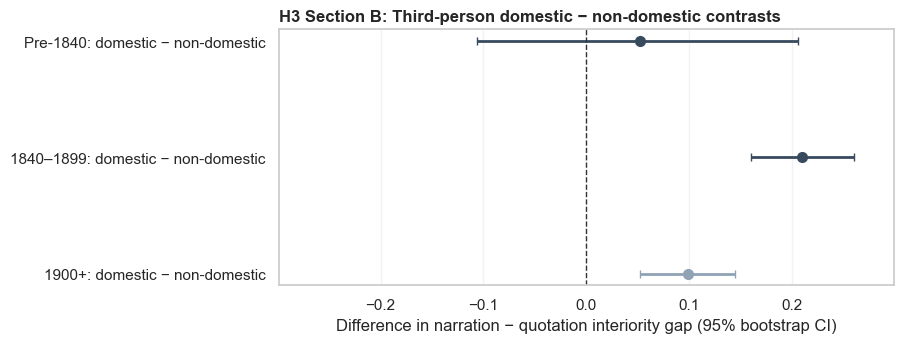

In [21]:
h3b_domestic_contrast_labels = [
    "Pre-1840: domestic − non-domestic",
    "1840–1899: domestic − non-domestic",
    "1900+: domestic − non-domestic",
]
forest_plot(
    h3b_third_person_domestic_non_domestic_contrasts,
    h3b_domestic_contrast_labels,
    "H3 Section B: Third-person domestic − non-domestic contrasts",
    "Difference in narration − quotation interiority gap (95% bootstrap CI)",
    "h3b_third_person_domestic_minus_non_domestic_contrasts_forest",
)


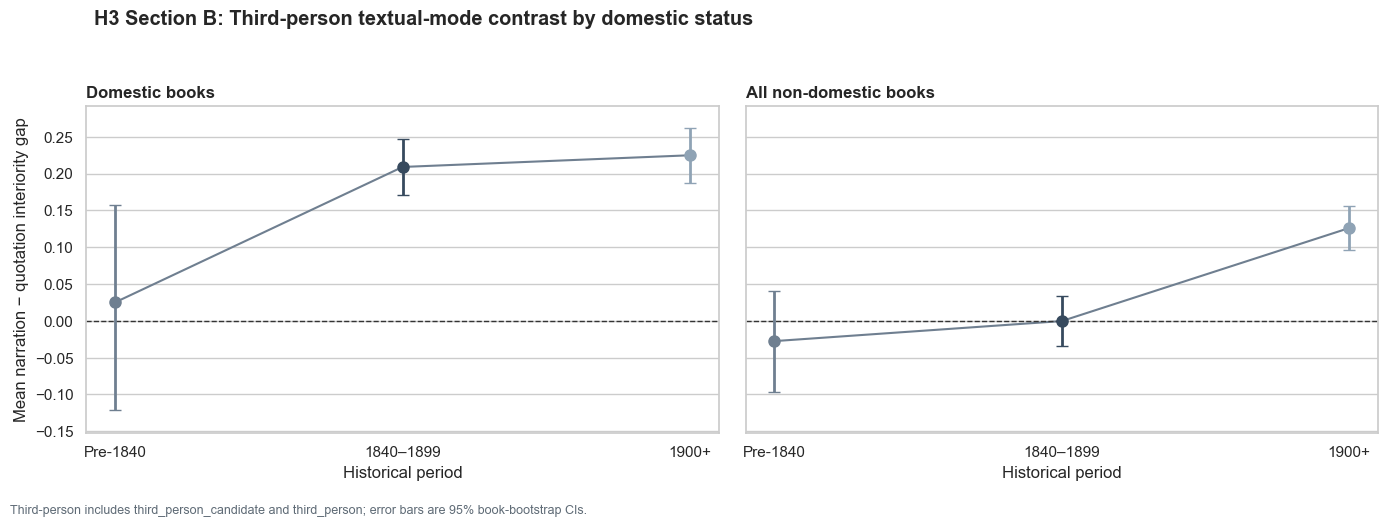

In [22]:
h3b_plot_tables = [
    (h3b_third_person_period_means.loc[h3b_third_person_period_means["group"].eq(group)].reset_index(drop=True), group)
    for group in ["Domestic books", "All non-domestic books"]
]
h3b_ci_bounds = pd.concat(
    [table[["ci_lower", "ci_upper"]] for table, _ in h3b_plot_tables], ignore_index=True
)
h3b_y_min = min(0, h3b_ci_bounds["ci_lower"].min())
h3b_y_max = max(0, h3b_ci_bounds["ci_upper"].max())
h3b_y_padding = 0.08 * (h3b_y_max - h3b_y_min)
h3b_common_ylim = (h3b_y_min - h3b_y_padding, h3b_y_max + h3b_y_padding)
h3b_x = np.arange(len(TIME_PERIOD_ORDER))

def draw_h3b_third_person_panel(ax, table, panel_title):
    for index, period in enumerate(TIME_PERIOD_ORDER):
        row = table.iloc[index]
        color = PERIOD_COLORS[PERIOD_LABELS[period]]
        ax.errorbar(
            h3b_x[index], row["estimate"],
            yerr=[[row["estimate"] - row["ci_lower"]], [row["ci_upper"] - row["estimate"]]],
            fmt="o", color=color, ecolor=color, capsize=4, markersize=8, linewidth=2, zorder=3,
        )
    ax.plot(h3b_x, table["estimate"], color="#6F7F90", linewidth=1.5, zorder=1)
    ax.axhline(0, color="#333333", linewidth=1, linestyle="--")
    ax.set_xticks(h3b_x, PUBLICATION_PERIODS)
    ax.set_xlabel("Historical period")
    ax.set_title(panel_title, loc="left", fontweight="bold")
    ax.set_ylim(h3b_common_ylim)
    ax.grid(axis="x", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.2), sharey=True)
for ax, (table, panel_title) in zip(axes, h3b_plot_tables):
    draw_h3b_third_person_panel(ax, table, panel_title)
axes[0].set_ylabel("Mean narration − quotation interiority gap")
fig.suptitle("H3 Section B: Third-person textual-mode contrast by domestic status", x=0.07, ha="left", fontweight="bold")
fig.text(
    0.01, 0.01,
    "Third-person includes third_person_candidate and third_person; error bars are 95% book-bootstrap CIs.",
    fontsize=9, color="#5F6B76",
)
fig.tight_layout(rect=[0, 0.04, 1, 0.94])
save_figure(fig, FIGURE_DIR, "h3b_third_person_domestic_and_non_domestic_period_means")
plt.show()

for table, panel_title, stem in [
    (h3b_plot_tables[0][0], "H3 Section B: Third-person domestic books", "h3b_third_person_domestic_period_means"),
    (h3b_plot_tables[1][0], "H3 Section B: Third-person all non-domestic books", "h3b_third_person_non_domestic_period_means"),
]:
    standalone_fig, standalone_ax = plt.subplots(figsize=(8.4, 5.0))
    draw_h3b_third_person_panel(standalone_ax, table, panel_title)
    standalone_ax.set_ylabel("Mean narration − quotation interiority gap")
    standalone_fig.tight_layout()
    save_figure(standalone_fig, FIGURE_DIR, stem)
    plt.close(standalone_fig)


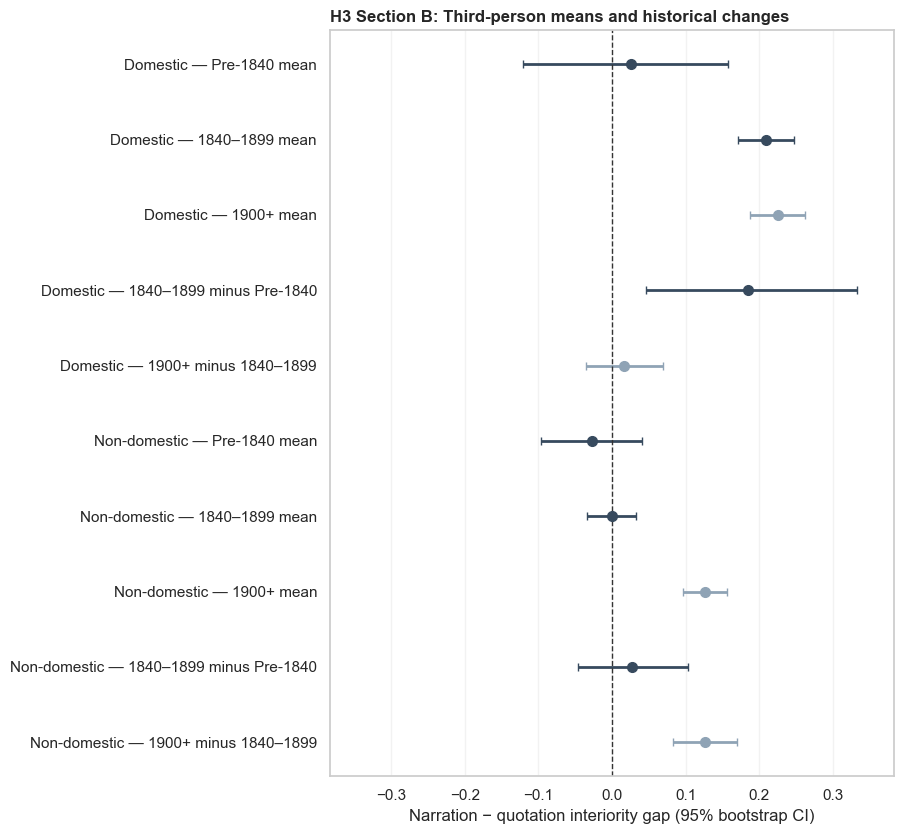

#### Section B factual summary

Domestic books: the third-person contrast increased by 0.184 from Pre-1840 to 1840–1899 (95% CI 0.046 to 0.333; entirely above zero). 

All non-domestic books: the third-person contrast increased by 0.027 from Pre-1840 to 1840–1899 (95% CI -0.046 to 0.103; spans zero).

In [23]:
h3b_forest_parts = []
h3b_forest_labels = []
for group, short_group in [("Domestic books", "Domestic"), ("All non-domestic books", "Non-domestic")]:
    group_means = h3b_third_person_period_means.loc[h3b_third_person_period_means["group"].eq(group)]
    group_changes = h3b_third_person_changes.loc[h3b_third_person_changes["group"].eq(group)]
    h3b_forest_parts.extend([group_means, group_changes])
    h3b_forest_labels.extend([
        f"{short_group} — Pre-1840 mean",
        f"{short_group} — 1840–1899 mean",
        f"{short_group} — 1900+ mean",
        f"{short_group} — 1840–1899 minus Pre-1840",
        f"{short_group} — 1900+ minus 1840–1899",
    ])
h3b_third_person_forest_data = pd.concat(h3b_forest_parts, ignore_index=True)
forest_plot(
    h3b_third_person_forest_data,
    h3b_forest_labels,
    "H3 Section B: Third-person means and historical changes",
    "Narration − quotation interiority gap (95% bootstrap CI)",
    "h3b_third_person_means_and_historical_changes_forest",
)

h3b_primary_summaries = []
for group in ["Domestic books", "All non-domestic books"]:
    row = h3b_third_person_changes.loc[
        h3b_third_person_changes["group"].eq(group)
        & h3b_third_person_changes["interpretation_scope"].eq("primary")
    ].iloc[0]
    direction = "increased" if row["estimate"] > 0 else "decreased"
    h3b_primary_summaries.append(
        f"{group}: the third-person contrast {direction} by {abs(row['estimate']):.3f} from Pre-1840 to 1840–1899 "
        f"(95% CI {row['ci_lower']:.3f} to {row['ci_upper']:.3f}; {interval_position(row['ci_lower'], row['ci_upper'])})."
    )
display(Markdown("#### Section B factual summary\n\n" + " \n\n".join(h3b_primary_summaries)))


## Secondary Analysis — Author Gender

This section is a secondary extension of H2, not one of the three primary hypotheses. Female- and male-authored books are compared within period after standardizing both groups to the same fixed domestic/non-domestic composition used in the adjusted protagonist analysis. Unknown author gender is excluded. Bootstrap resampling occurs within period × domestic-status × author-gender cells, and historical changes are calculated within iteration. Parallel unstandardized and genre-standardized analyses compare female- and male-author means within female- and male-protagonist books, restricted to `protagonist_analysis_status == "included"`. The standardized version uses the same fixed pooled domestic/non-domestic weights as the other adjusted gender analyses.


In [24]:
# Secondary analysis: author gender, standardized for domestic-fiction status within period
AUTHOR_LEVELS = ["female", "male"]
AUTHOR_LABELS = {"female": "Female", "male": "Male"}
author_data = book_data.loc[
    book_data["time_period"].notna()
    & book_data["author_gender"].isin(AUTHOR_LEVELS)
    & book_data["is_domestic"].isin([0, 1])
    & book_data["avg_interiority_score"].notna(),
    ["gutenberg_id", "time_period", "is_domestic", "author_gender", "avg_interiority_score"],
].copy()
author_data["is_domestic"] = author_data["is_domestic"].astype(int)

author_summary = (
    author_data.assign(
        period=author_data["time_period"].map(PERIOD_LABELS),
        gender=author_data["author_gender"].map(AUTHOR_LABELS),
    )
    .groupby(["time_period", "period", "author_gender", "gender"], observed=True, as_index=False)
    .agg(n_books=("gutenberg_id", "nunique"), mean_interiority=("avg_interiority_score", "mean"))
)
author_summary["time_period"] = pd.Categorical(
    author_summary["time_period"], categories=TIME_PERIOD_ORDER, ordered=True
)
author_summary["author_gender"] = pd.Categorical(
    author_summary["author_gender"], categories=AUTHOR_LEVELS, ordered=True
)
author_summary = author_summary.sort_values(["time_period", "author_gender"]).reset_index(drop=True)

# Keep the pre-existing author-bootstrap stream independent of the now-restricted H2 cohort.
# These alignment draws reproduce the former RNG position; they are not author estimates.
author_rng = np.random.default_rng(h2_gender_seed)
for period in TIME_PERIOD_ORDER:
    for protagonist_gender in PROTAGONIST_LEVELS:
        alignment_values = book_data.loc[
            book_data["time_period"].eq(period)
            & book_data["protagonist_gender"].eq(protagonist_gender)
            & book_data["avg_interiority_score"].notna(),
            "avg_interiority_score",
        ].to_numpy(float)
        bootstrap_mean_draws(alignment_values, author_rng)

author_values = {}
author_draws = {}
author_weights = {}
author_adjusted_means = {}
author_adjusted_draws = {}
for period in TIME_PERIOD_ORDER:
    period_data = author_data.loc[author_data["time_period"].eq(period)]
    weights = GENDER_STANDARDIZATION_WEIGHTS
    author_weights[period] = weights.to_dict()
    for gender in AUTHOR_LEVELS:
        adjusted_mean = 0.0
        adjusted_draws = np.zeros(BOOTSTRAP_REPETITIONS)
        for domestic_status in [0, 1]:
            values = period_data.loc[
                period_data["author_gender"].eq(gender)
                & period_data["is_domestic"].eq(domestic_status),
                "avg_interiority_score",
            ].to_numpy(float)
            if len(values) == 0:
                raise ValueError(f"Empty author-gender bootstrap cell: {period}, {domestic_status}, {gender}")
            draws = bootstrap_mean_draws(values, author_rng)
            author_values[(period, domestic_status, gender)] = values
            author_draws[(period, domestic_status, gender)] = draws
            adjusted_mean += weights.loc[domestic_status] * values.mean()
            adjusted_draws += weights.loc[domestic_status] * draws
        author_adjusted_means[(period, gender)] = adjusted_mean
        author_adjusted_draws[(period, gender)] = adjusted_draws

author_gap_estimates = {
    period: author_adjusted_means[(period, "female")] - author_adjusted_means[(period, "male")]
    for period in TIME_PERIOD_ORDER
}
author_gap_draws = {
    period: author_adjusted_draws[(period, "female")] - author_adjusted_draws[(period, "male")]
    for period in TIME_PERIOD_ORDER
}

author_effect_rows = []
for period in TIME_PERIOD_ORDER:
    lower, upper = percentile_interval(author_gap_draws[period])
    n_female = sum(len(author_values[(period, status, "female")]) for status in [0, 1])
    n_male = sum(len(author_values[(period, status, "male")]) for status in [0, 1])
    weights = author_weights[period]
    author_effect_rows.append(
        {
            "hypothesis": "H2", "analysis_component": "secondary_author_domestic_standardized",
            "estimate_type": "direct_contrast",
            "period_or_contrast": f"{PERIOD_LABELS[period]}: female − male author",
            "group": "Female − male author", "estimate": author_gap_estimates[period],
            "ci_lower": lower, "ci_upper": upper, "n_books": n_female + n_male,
            "n_female": n_female, "n_male": n_male, "n_mixed": np.nan,
            "book_counts": f"female={n_female}; male={n_male}",
            "adjustment": f"Fixed pooled author analysis mix: non-domestic={weights[0]:.3f}; domestic={weights[1]:.3f}",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        }
    )

for earlier, later, label, scope in [
    ("<1840", "1840-1899", "1840–1899 author gap − Pre-1840 author gap", "primary"),
    ("1840-1899", "1900+", "1900+ author gap − 1840–1899 author gap", "extension"),
]:
    change_draws = author_gap_draws[later] - author_gap_draws[earlier]
    lower, upper = percentile_interval(change_draws)
    n_female = sum(len(author_values[(period, status, "female")]) for period in [earlier, later] for status in [0, 1])
    n_male = sum(len(author_values[(period, status, "male")]) for period in [earlier, later] for status in [0, 1])
    author_effect_rows.append(
        {
            "hypothesis": "H2", "analysis_component": "secondary_author_domestic_standardized",
            "estimate_type": "historical_change", "period_or_contrast": label,
            "group": "Change in female − male author gap",
            "estimate": author_gap_estimates[later] - author_gap_estimates[earlier],
            "ci_lower": lower, "ci_upper": upper, "n_books": n_female + n_male,
            "n_female": n_female, "n_male": n_male, "n_mixed": np.nan,
            "book_counts": f"{PERIOD_LABELS[earlier]} and {PERIOD_LABELS[later]}: female={n_female}; male={n_male}",
            "adjustment": "Fixed pooled author analysis domestic-status composition across all periods",
            "interpretation_scope": scope,
        }
    )
author_effects = pd.DataFrame(author_effect_rows)


# Unadjusted author-gender mean draws for the descriptive line-chart CIs.
author_unadjusted_rng = np.random.default_rng(h2_gender_seed.spawn(1)[0])
author_unadjusted_values = {}
author_unadjusted_draws = {}
for period in TIME_PERIOD_ORDER:
    for gender in AUTHOR_LEVELS:
        values = author_data.loc[
            author_data["time_period"].eq(period)
            & author_data["author_gender"].eq(gender),
            "avg_interiority_score",
        ].to_numpy(float)
        author_unadjusted_values[(period, gender)] = values
        author_unadjusted_draws[(period, gender)] = bootstrap_mean_draws(
            values, author_unadjusted_rng
        )


In [25]:
display(Markdown("#### Author-gender counts and unadjusted equal-book means"))
display(author_summary[["period", "gender", "n_books", "mean_interiority"]].round(4))
display(Markdown(
    f"**Adjustment.** All periods use {GENDER_STANDARDIZATION_WEIGHTS.loc[0]:.1%} non-domestic / "
    f"{GENDER_STANDARDIZATION_WEIGHTS.loc[1]:.1%} domestic, so historical changes compare author-gender gaps at a constant genre composition."
))
display(Markdown("#### Secondary author-gender contrasts"))
display(author_effects[["estimate_type", "period_or_contrast", "estimate", "ci_lower", "ci_upper", "book_counts", "interpretation_scope"]].round(4))


#### Author-gender counts and unadjusted equal-book means

,period,gender,n_books,mean_interiority
0,Pre-1840,Female,48,1.2938
1,Pre-1840,Male,61,1.0549
2,1840–1899,Female,168,1.1824
3,1840–1899,Male,384,1.0183
4,1900+,Female,181,1.1279
5,1900+,Male,499,1.0516


**Adjustment.** All periods use 65.5% non-domestic / 34.5% domestic, so historical changes compare author-gender gaps at a constant genre composition.

#### Secondary author-gender contrasts

,estimate_type,period_or_contrast,estimate,ci_lower,ci_upper,book_counts,interpretation_scope
0,direct_contrast,Pre-1840: female − male author,0.2176,0.1153,0.3202,female=48; male=61,primary
1,direct_contrast,1840–1899: female − male author,0.1324,0.0983,0.1684,female=168; male=384,primary
2,direct_contrast,1900+: female − male author,0.0352,-0.0002,0.0692,female=181; male=499,extension
3,historical_change,1840–1899 author gap − Pre-1840 author gap,-0.0851,-0.1938,0.0240,Pre-1840 and 1840–1899: female=216; male=445,primary
4,historical_change,1900+ author gap − 1840–1899 author gap,-0.0972,-0.1474,-0.0493,1840–1899 and 1900+: female=349; male=883,extension


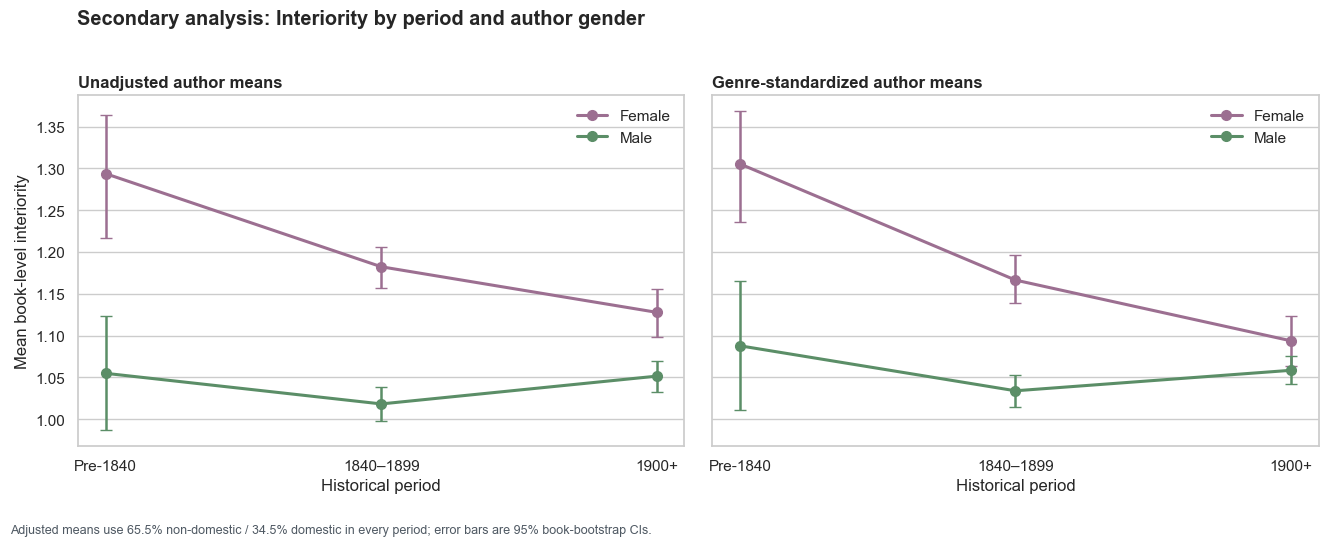

In [26]:
x = np.arange(len(TIME_PERIOD_ORDER))
fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.4), sharex=True, sharey=True)
for gender, color in [("female", "#9C6F91"), ("male", "#5B8E67")]:
    estimates = np.array([author_unadjusted_values[(period, gender)].mean() for period in TIME_PERIOD_ORDER])
    intervals = np.array([percentile_interval(author_unadjusted_draws[(period, gender)]) for period in TIME_PERIOD_ORDER])
    axes[0].plot(x, estimates, marker="o", linewidth=2.2, markersize=7, color=color, label=AUTHOR_LABELS[gender], zorder=3)
    axes[0].errorbar(x, estimates, yerr=np.vstack([estimates - intervals[:, 0], intervals[:, 1] - estimates]), fmt="none", ecolor=color, elinewidth=1.8, capsize=4, zorder=2)

    adjusted_estimates = np.array([author_adjusted_means[(period, gender)] for period in TIME_PERIOD_ORDER])
    adjusted_intervals = np.array([percentile_interval(author_adjusted_draws[(period, gender)]) for period in TIME_PERIOD_ORDER])
    axes[1].plot(x, adjusted_estimates, marker="o", linewidth=2.2, markersize=7, color=color, label=AUTHOR_LABELS[gender], zorder=3)
    axes[1].errorbar(x, adjusted_estimates, yerr=np.vstack([adjusted_estimates - adjusted_intervals[:, 0], adjusted_intervals[:, 1] - adjusted_estimates]), fmt="none", ecolor=color, elinewidth=1.8, capsize=4, zorder=2)

for ax, title in zip(axes, ["Unadjusted author means", "Genre-standardized author means"]):
    ax.set_xticks(x, PUBLICATION_PERIODS)
    ax.set_xlabel("Historical period")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.legend(frameon=False)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Mean book-level interiority")
fig.suptitle("Secondary analysis: Interiority by period and author gender", x=0.06, ha="left", fontweight="bold")
fig.text(0.01, 0.01, f"Adjusted means use {GENDER_STANDARDIZATION_WEIGHTS.loc[0]:.1%} non-domestic / {GENDER_STANDARDIZATION_WEIGHTS.loc[1]:.1%} domestic in every period; error bars are 95% book-bootstrap CIs.", fontsize=9, color="#4F5963")
fig.tight_layout(rect=[0, 0.05, 1, 0.96])
save_figure(fig, FIGURE_DIR, "secondary_author_gender_period_means")
plt.show()


#### Author-gender contrasts within included female- and male-protagonist books

,estimate_type,protagonist_gender,period_or_contrast,estimate,ci_lower,ci_upper,n_books,n_female_authors,n_male_authors,book_counts,interpretation_scope
0,direct_contrast,Female,Pre-1840: female − male author,0.0333,-0.0479,0.1104,30,24,6,female author=24; male author=6,primary
1,direct_contrast,Female,1840–1899: female − male author,0.1033,0.0473,0.1592,152,94,58,female author=94; male author=58,primary
2,direct_contrast,Female,1900+: female − male author,0.0300,-0.0272,0.0851,161,87,74,female author=87; male author=74,extension
3,historical_change,Female,1840–1899 author gap − Pre-1840 author gap,0.0699,-0.0267,0.1678,182,118,64,female author=118; male author=64,primary
4,historical_change,Female,1900+ author gap − 1840–1899 author gap,-0.0732,-0.1523,0.0058,313,181,132,female author=181; male author=132,extension
5,direct_contrast,Male,Pre-1840: female − male author,0.1433,-0.0447,0.3201,43,14,29,female author=14; male author=29,primary
6,direct_contrast,Male,1840–1899: female − male author,0.2068,0.1512,0.2633,218,36,182,female author=36; male author=182,primary
7,direct_contrast,Male,1900+: female − male author,0.0511,-0.0245,0.1274,287,39,248,female author=39; male author=248,extension
8,historical_change,Male,1840–1899 author gap − Pre-1840 author gap,0.0635,-0.1237,0.2568,261,50,211,female author=50; male author=211,primary
9,historical_change,Male,1900+ author gap − 1840–1899 author gap,-0.1556,-0.2538,-0.0599,505,75,430,female author=75; male author=430,extension


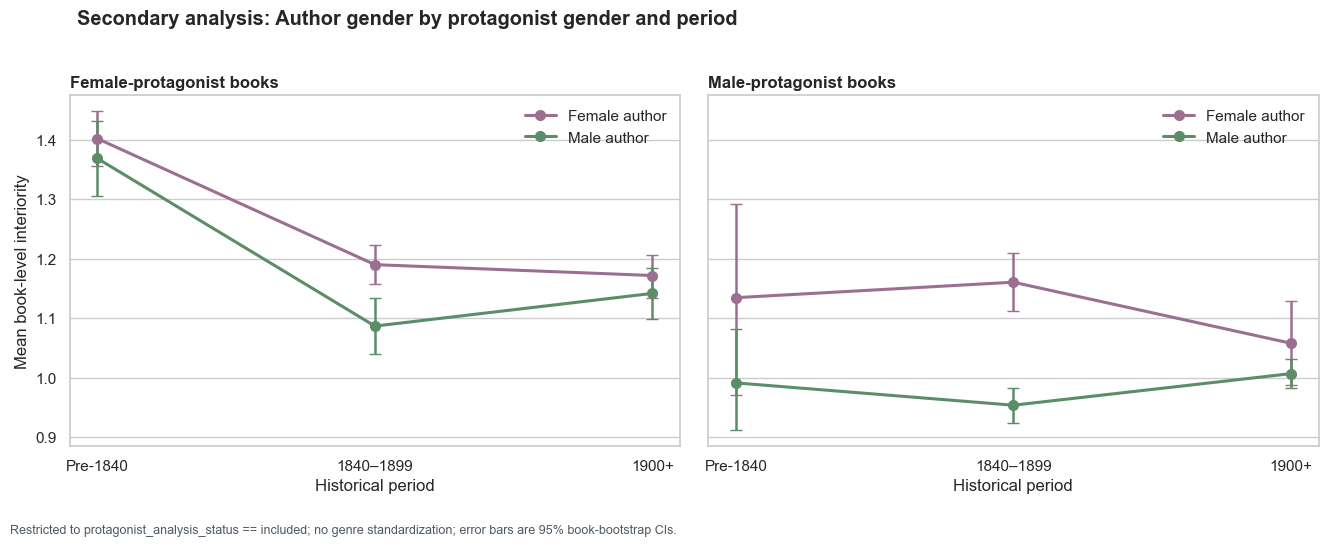

In [27]:
# Unstandardized author-gender analysis within included female- and male-protagonist books.
AUTHOR_PROTAGONIST_LEVELS = ["F", "M"]
AUTHOR_PROTAGONIST_LABELS = {"F": "Female-protagonist books", "M": "Male-protagonist books"}
author_protagonist_data = book_data.loc[
    book_data["protagonist_analysis_status"].eq("included")
    & book_data["protagonist_gender"].isin(AUTHOR_PROTAGONIST_LEVELS)
    & book_data["author_gender"].isin(AUTHOR_LEVELS)
    & book_data["time_period"].notna()
    & book_data["avg_interiority_score"].notna(),
    ["gutenberg_id", "time_period", "is_domestic", "protagonist_gender", "protagonist_analysis_status", "author_gender", "avg_interiority_score"],
].copy()
if not author_protagonist_data["protagonist_analysis_status"].eq("included").all():
    raise AssertionError("Every stratified author-gender book must have protagonist_analysis_status == 'included'.")
author_protagonist_data["is_domestic"] = author_protagonist_data["is_domestic"].astype(int)

author_protagonist_rng = np.random.default_rng(np.random.SeedSequence([BOOTSTRAP_SEED, 404]))
author_protagonist_values = {}
author_protagonist_draws = {}
author_protagonist_mean_rows = []
for protagonist_gender in AUTHOR_PROTAGONIST_LEVELS:
    for period in TIME_PERIOD_ORDER:
        for author_gender in AUTHOR_LEVELS:
            values = author_protagonist_data.loc[
                author_protagonist_data["protagonist_gender"].eq(protagonist_gender)
                & author_protagonist_data["time_period"].eq(period)
                & author_protagonist_data["author_gender"].eq(author_gender),
                "avg_interiority_score",
            ].to_numpy(float)
            draws = bootstrap_mean_draws(values, author_protagonist_rng)
            lower, upper = percentile_interval(draws)
            author_protagonist_values[(protagonist_gender, period, author_gender)] = values
            author_protagonist_draws[(protagonist_gender, period, author_gender)] = draws
            author_protagonist_mean_rows.append({
                "protagonist_gender": PROTAGONIST_LABELS[protagonist_gender],
                "period": PERIOD_LABELS[period],
                "author_gender": AUTHOR_LABELS[author_gender],
                "n_books": len(values),
                "estimate": values.mean(),
                "ci_lower": lower,
                "ci_upper": upper,
                "adjustment": "None; protagonist_analysis_status == included",
            })

author_protagonist_period_means = pd.DataFrame(author_protagonist_mean_rows)
author_protagonist_period_means.to_csv(
    TABLE_DIR / "secondary_author_gender_by_protagonist_gender_period_means.csv", index=False
)

author_protagonist_contrast_rows = []
for protagonist_gender in AUTHOR_PROTAGONIST_LEVELS:
    period_gap_estimates = {}
    period_gap_draws = {}
    for period in TIME_PERIOD_ORDER:
        female_values = author_protagonist_values[(protagonist_gender, period, "female")]
        male_values = author_protagonist_values[(protagonist_gender, period, "male")]
        gap_draws = (
            author_protagonist_draws[(protagonist_gender, period, "female")]
            - author_protagonist_draws[(protagonist_gender, period, "male")]
        )
        lower, upper = percentile_interval(gap_draws)
        gap_estimate = female_values.mean() - male_values.mean()
        period_gap_estimates[period] = gap_estimate
        period_gap_draws[period] = gap_draws
        author_protagonist_contrast_rows.append({
            "estimate_type": "direct_contrast",
            "protagonist_gender": PROTAGONIST_LABELS[protagonist_gender],
            "period_or_contrast": f"{PERIOD_LABELS[period]}: female − male author",
            "estimate": gap_estimate,
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": len(female_values) + len(male_values),
            "n_female_authors": len(female_values),
            "n_male_authors": len(male_values),
            "book_counts": f"female author={len(female_values)}; male author={len(male_values)}",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        })
    for earlier, later, label, scope in [
        ("<1840", "1840-1899", "1840–1899 author gap − Pre-1840 author gap", "primary"),
        ("1840-1899", "1900+", "1900+ author gap − 1840–1899 author gap", "extension"),
    ]:
        change_draws = period_gap_draws[later] - period_gap_draws[earlier]
        lower, upper = percentile_interval(change_draws)
        n_female = sum(len(author_protagonist_values[(protagonist_gender, p, "female")]) for p in [earlier, later])
        n_male = sum(len(author_protagonist_values[(protagonist_gender, p, "male")]) for p in [earlier, later])
        author_protagonist_contrast_rows.append({
            "estimate_type": "historical_change",
            "protagonist_gender": PROTAGONIST_LABELS[protagonist_gender],
            "period_or_contrast": label,
            "estimate": period_gap_estimates[later] - period_gap_estimates[earlier],
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": n_female + n_male,
            "n_female_authors": n_female,
            "n_male_authors": n_male,
            "book_counts": f"female author={n_female}; male author={n_male}",
            "interpretation_scope": scope,
        })

author_protagonist_contrasts = pd.DataFrame(author_protagonist_contrast_rows)
author_protagonist_contrasts.to_csv(
    TABLE_DIR / "secondary_author_gender_by_protagonist_gender_contrasts.csv", index=False
)
display(Markdown("#### Author-gender contrasts within included female- and male-protagonist books"))
display(author_protagonist_contrasts.round(4))

x = np.arange(len(TIME_PERIOD_ORDER))
fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.4), sharex=True, sharey=True)
for ax, protagonist_gender in zip(axes, AUTHOR_PROTAGONIST_LEVELS):
    for author_gender, color in [("female", "#9C6F91"), ("male", "#5B8E67")]:
        estimates = np.array([
            author_protagonist_values[(protagonist_gender, period, author_gender)].mean()
            for period in TIME_PERIOD_ORDER
        ])
        intervals = np.array([
            percentile_interval(author_protagonist_draws[(protagonist_gender, period, author_gender)])
            for period in TIME_PERIOD_ORDER
        ])
        ax.plot(
            x, estimates, marker="o", linewidth=2.2, markersize=7,
            color=color, label=f"{AUTHOR_LABELS[author_gender]} author", zorder=3,
        )
        ax.errorbar(
            x, estimates,
            yerr=np.vstack([estimates - intervals[:, 0], intervals[:, 1] - estimates]),
            fmt="none", ecolor=color, elinewidth=1.8, capsize=4, zorder=2,
        )
    ax.set_xticks(x, PUBLICATION_PERIODS)
    ax.set_xlabel("Historical period")
    ax.set_title(AUTHOR_PROTAGONIST_LABELS[protagonist_gender], loc="left", fontweight="bold")
    ax.legend(frameon=False)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Mean book-level interiority")
fig.suptitle("Secondary analysis: Author gender by protagonist gender and period", x=0.06, ha="left", fontweight="bold")
fig.text(
    0.01, 0.01,
    "Restricted to protagonist_analysis_status == included; no genre standardization; error bars are 95% book-bootstrap CIs.",
    fontsize=9, color="#4F5963",
)
fig.tight_layout(rect=[0, 0.05, 1, 0.96])
save_figure(fig, FIGURE_DIR, "secondary_author_gender_by_protagonist_gender_period_means")
plt.show()


#### Genre-standardized author-gender contrasts within included female- and male-protagonist books

,estimate_type,protagonist_gender,period_or_contrast,estimate,ci_lower,ci_upper,n_books,n_female_authors,n_male_authors,estimable,interpretation_scope
0,adjusted_direct_contrast,Female,Pre-1840: adjusted female − male author,0.0290,-0.0452,0.1028,30,24,6,True,primary
1,adjusted_direct_contrast,Female,1840–1899: adjusted female − male author,0.0920,0.0303,0.1571,152,94,58,True,primary
2,adjusted_direct_contrast,Female,1900+: adjusted female − male author,0.0439,-0.0181,0.1028,161,87,74,True,extension
3,adjusted_historical_change,Female,1840–1899 adjusted author gap − Pre-1840 adjus...,0.0630,-0.0322,0.1597,182,118,64,True,primary
4,adjusted_historical_change,Female,1900+ adjusted author gap − 1840–1899 adjusted...,-0.0481,-0.1339,0.0352,313,181,132,True,extension
5,adjusted_direct_contrast,Male,Pre-1840: adjusted female − male author,NaN,NaN,NaN,43,14,29,False,primary
6,adjusted_direct_contrast,Male,1840–1899: adjusted female − male author,0.1779,0.1176,0.2376,218,36,182,True,primary
7,adjusted_direct_contrast,Male,1900+: adjusted female − male author,0.0364,-0.0321,0.1052,287,39,248,True,extension
8,adjusted_historical_change,Male,1840–1899 adjusted author gap − Pre-1840 adjus...,NaN,NaN,NaN,261,50,211,False,primary
9,adjusted_historical_change,Male,1900+ adjusted author gap − 1840–1899 adjusted...,-0.1415,-0.2313,-0.0517,505,75,430,True,extension


**Estimability note.** The Pre-1840 male-protagonist × female-author domestic cell contains no books. Its standardized mean, period gap, and dependent primary historical change are therefore reported as NA.

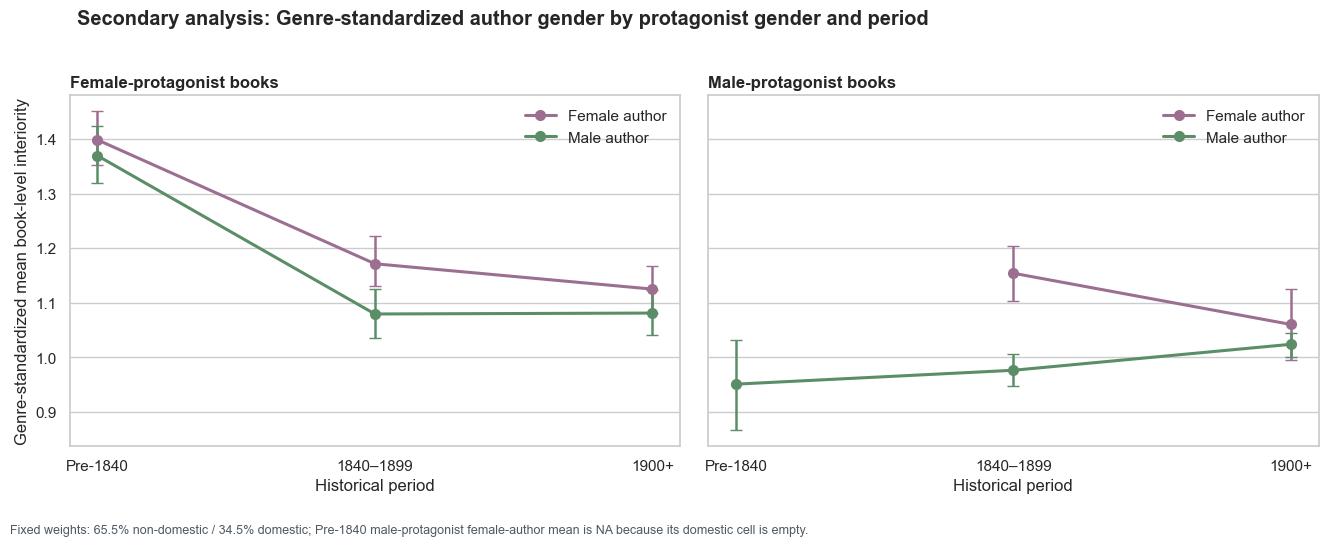

In [28]:
# Genre-standardized version of the included protagonist-gender-stratified author analysis.
author_protagonist_adjusted_rng = np.random.default_rng(np.random.SeedSequence([BOOTSTRAP_SEED, 405]))
author_protagonist_adjusted_means = {}
author_protagonist_adjusted_draws = {}
author_protagonist_adjusted_mean_rows = []
for protagonist_gender in AUTHOR_PROTAGONIST_LEVELS:
    for period in TIME_PERIOD_ORDER:
        for author_gender in AUTHOR_LEVELS:
            adjusted_mean = 0.0
            adjusted_draws = np.zeros(BOOTSTRAP_REPETITIONS)
            cell_counts = {}
            estimable = True
            for domestic_status in [0, 1]:
                values = author_protagonist_data.loc[
                    author_protagonist_data["protagonist_gender"].eq(protagonist_gender)
                    & author_protagonist_data["time_period"].eq(period)
                    & author_protagonist_data["author_gender"].eq(author_gender)
                    & author_protagonist_data["is_domestic"].eq(domestic_status),
                    "avg_interiority_score",
                ].to_numpy(float)
                cell_counts[domestic_status] = len(values)
                if len(values) == 0:
                    estimable = False
                    continue
                cell_draws = bootstrap_mean_draws(values, author_protagonist_adjusted_rng)
                adjusted_mean += GENDER_STANDARDIZATION_WEIGHTS.loc[domestic_status] * values.mean()
                adjusted_draws += GENDER_STANDARDIZATION_WEIGHTS.loc[domestic_status] * cell_draws
            if estimable:
                lower, upper = percentile_interval(adjusted_draws)
            else:
                adjusted_mean = np.nan
                adjusted_draws = np.full(BOOTSTRAP_REPETITIONS, np.nan)
                lower, upper = np.nan, np.nan
            author_protagonist_adjusted_means[(protagonist_gender, period, author_gender)] = adjusted_mean
            author_protagonist_adjusted_draws[(protagonist_gender, period, author_gender)] = adjusted_draws
            author_protagonist_adjusted_mean_rows.append({
                "protagonist_gender": PROTAGONIST_LABELS[protagonist_gender],
                "period": PERIOD_LABELS[period],
                "author_gender": AUTHOR_LABELS[author_gender],
                "estimate": adjusted_mean,
                "ci_lower": lower,
                "ci_upper": upper,
                "n_books": cell_counts[0] + cell_counts[1],
                "n_non_domestic": cell_counts[0],
                "n_domestic": cell_counts[1],
                "estimable": estimable,
                "adjustment": f"Fixed mix: non-domestic={GENDER_STANDARDIZATION_WEIGHTS.loc[0]:.3f}; domestic={GENDER_STANDARDIZATION_WEIGHTS.loc[1]:.3f}",
            })

author_protagonist_adjusted_period_means = pd.DataFrame(author_protagonist_adjusted_mean_rows)
author_protagonist_adjusted_period_means.to_csv(
    TABLE_DIR / "secondary_author_gender_by_protagonist_gender_adjusted_period_means.csv", index=False
)

author_protagonist_adjusted_contrast_rows = []
for protagonist_gender in AUTHOR_PROTAGONIST_LEVELS:
    period_gap_estimates = {}
    period_gap_draws = {}
    for period in TIME_PERIOD_ORDER:
        female_mean = author_protagonist_adjusted_means[(protagonist_gender, period, "female")]
        male_mean = author_protagonist_adjusted_means[(protagonist_gender, period, "male")]
        female_draws = author_protagonist_adjusted_draws[(protagonist_gender, period, "female")]
        male_draws = author_protagonist_adjusted_draws[(protagonist_gender, period, "male")]
        estimable = np.isfinite(female_mean) and np.isfinite(male_mean)
        if estimable:
            gap_estimate = female_mean - male_mean
            gap_draws = female_draws - male_draws
            lower, upper = percentile_interval(gap_draws)
        else:
            gap_estimate = np.nan
            gap_draws = np.full(BOOTSTRAP_REPETITIONS, np.nan)
            lower, upper = np.nan, np.nan
        period_gap_estimates[period] = gap_estimate
        period_gap_draws[period] = gap_draws
        female_n = sum(
            len(author_protagonist_data.loc[
                author_protagonist_data["protagonist_gender"].eq(protagonist_gender)
                & author_protagonist_data["time_period"].eq(period)
                & author_protagonist_data["author_gender"].eq("female")
                & author_protagonist_data["is_domestic"].eq(status)
            ]) for status in [0, 1]
        )
        male_n = sum(
            len(author_protagonist_data.loc[
                author_protagonist_data["protagonist_gender"].eq(protagonist_gender)
                & author_protagonist_data["time_period"].eq(period)
                & author_protagonist_data["author_gender"].eq("male")
                & author_protagonist_data["is_domestic"].eq(status)
            ]) for status in [0, 1]
        )
        author_protagonist_adjusted_contrast_rows.append({
            "estimate_type": "adjusted_direct_contrast",
            "protagonist_gender": PROTAGONIST_LABELS[protagonist_gender],
            "period_or_contrast": f"{PERIOD_LABELS[period]}: adjusted female − male author",
            "estimate": gap_estimate,
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": female_n + male_n,
            "n_female_authors": female_n,
            "n_male_authors": male_n,
            "estimable": estimable,
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        })
    for earlier, later, label, scope in [
        ("<1840", "1840-1899", "1840–1899 adjusted author gap − Pre-1840 adjusted author gap", "primary"),
        ("1840-1899", "1900+", "1900+ adjusted author gap − 1840–1899 adjusted author gap", "extension"),
    ]:
        estimable = np.isfinite(period_gap_estimates[earlier]) and np.isfinite(period_gap_estimates[later])
        if estimable:
            change_estimate = period_gap_estimates[later] - period_gap_estimates[earlier]
            change_draws = period_gap_draws[later] - period_gap_draws[earlier]
            lower, upper = percentile_interval(change_draws)
        else:
            change_estimate, lower, upper = np.nan, np.nan, np.nan
        n_female = sum(len(author_protagonist_values[(protagonist_gender, p, "female")]) for p in [earlier, later])
        n_male = sum(len(author_protagonist_values[(protagonist_gender, p, "male")]) for p in [earlier, later])
        author_protagonist_adjusted_contrast_rows.append({
            "estimate_type": "adjusted_historical_change",
            "protagonist_gender": PROTAGONIST_LABELS[protagonist_gender],
            "period_or_contrast": label,
            "estimate": change_estimate,
            "ci_lower": lower,
            "ci_upper": upper,
            "n_books": n_female + n_male,
            "n_female_authors": n_female,
            "n_male_authors": n_male,
            "estimable": estimable,
            "interpretation_scope": scope,
        })

author_protagonist_adjusted_contrasts = pd.DataFrame(author_protagonist_adjusted_contrast_rows)
author_protagonist_adjusted_contrasts.to_csv(
    TABLE_DIR / "secondary_author_gender_by_protagonist_gender_adjusted_contrasts.csv", index=False
)
display(Markdown("#### Genre-standardized author-gender contrasts within included female- and male-protagonist books"))
display(author_protagonist_adjusted_contrasts.round(4))
display(Markdown(
    "**Estimability note.** The Pre-1840 male-protagonist × female-author domestic cell contains no books. "
    "Its standardized mean, period gap, and dependent primary historical change are therefore reported as NA."
))

x = np.arange(len(TIME_PERIOD_ORDER))
fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.4), sharex=True, sharey=True)
for ax, protagonist_gender in zip(axes, AUTHOR_PROTAGONIST_LEVELS):
    for author_gender, color in [("female", "#9C6F91"), ("male", "#5B8E67")]:
        plot_rows = author_protagonist_adjusted_period_means.loc[
            author_protagonist_adjusted_period_means["protagonist_gender"].eq(PROTAGONIST_LABELS[protagonist_gender])
            & author_protagonist_adjusted_period_means["author_gender"].eq(AUTHOR_LABELS[author_gender])
        ].reset_index(drop=True)
        estimates = plot_rows["estimate"].to_numpy(float)
        lower = plot_rows["ci_lower"].to_numpy(float)
        upper = plot_rows["ci_upper"].to_numpy(float)
        ax.plot(
            x, estimates, marker="o", linewidth=2.2, markersize=7,
            color=color, label=f"{AUTHOR_LABELS[author_gender]} author", zorder=3,
        )
        ax.errorbar(
            x, estimates, yerr=np.vstack([estimates - lower, upper - estimates]),
            fmt="none", ecolor=color, elinewidth=1.8, capsize=4, zorder=2,
        )
    ax.set_xticks(x, PUBLICATION_PERIODS)
    ax.set_xlabel("Historical period")
    ax.set_title(AUTHOR_PROTAGONIST_LABELS[protagonist_gender], loc="left", fontweight="bold")
    ax.legend(frameon=False)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Genre-standardized mean book-level interiority")
fig.suptitle("Secondary analysis: Genre-standardized author gender by protagonist gender and period", x=0.06, ha="left", fontweight="bold")
fig.text(
    0.01, 0.01,
    f"Fixed weights: {GENDER_STANDARDIZATION_WEIGHTS.loc[0]:.1%} non-domestic / {GENDER_STANDARDIZATION_WEIGHTS.loc[1]:.1%} domestic; Pre-1840 male-protagonist female-author mean is NA because its domestic cell is empty.",
    fontsize=9, color="#4F5963",
)
fig.tight_layout(rect=[0, 0.05, 1, 0.96])
save_figure(fig, FIGURE_DIR, "secondary_author_gender_by_protagonist_gender_adjusted_period_means")
plt.show()


#### Author gender standardized to a common protagonist-gender composition

This analysis mirrors the earlier unadjusted-versus-adjusted author-gender figure, but standardizes to a fixed pooled female-/male-protagonist composition rather than a domestic/non-domestic composition. Its full analysis universe is restricted to `protagonist_analysis_status == "included"`, clearly classified F/M protagonists, and clearly classified female/male authors.


##### Counts by period × author gender × protagonist gender

,period,author_gender,protagonist_gender,n_books,pooled_standardization_weight,analysis_filter
0,Pre-1840,Female,Female,24,0.385,protagonist_analysis_status == included
1,Pre-1840,Female,Male,14,0.615,protagonist_analysis_status == included
2,Pre-1840,Male,Female,6,0.385,protagonist_analysis_status == included
3,Pre-1840,Male,Male,29,0.615,protagonist_analysis_status == included
4,1840–1899,Female,Female,94,0.385,protagonist_analysis_status == included
5,1840–1899,Female,Male,36,0.615,protagonist_analysis_status == included
6,1840–1899,Male,Female,58,0.385,protagonist_analysis_status == included
7,1840–1899,Male,Male,182,0.615,protagonist_analysis_status == included
8,1900+,Female,Female,87,0.385,protagonist_analysis_status == included
9,1900+,Female,Male,39,0.615,protagonist_analysis_status == included


**Fixed protagonist-gender target:** 38.5% female-protagonist / 61.5% male-protagonist in every period and author-gender group.

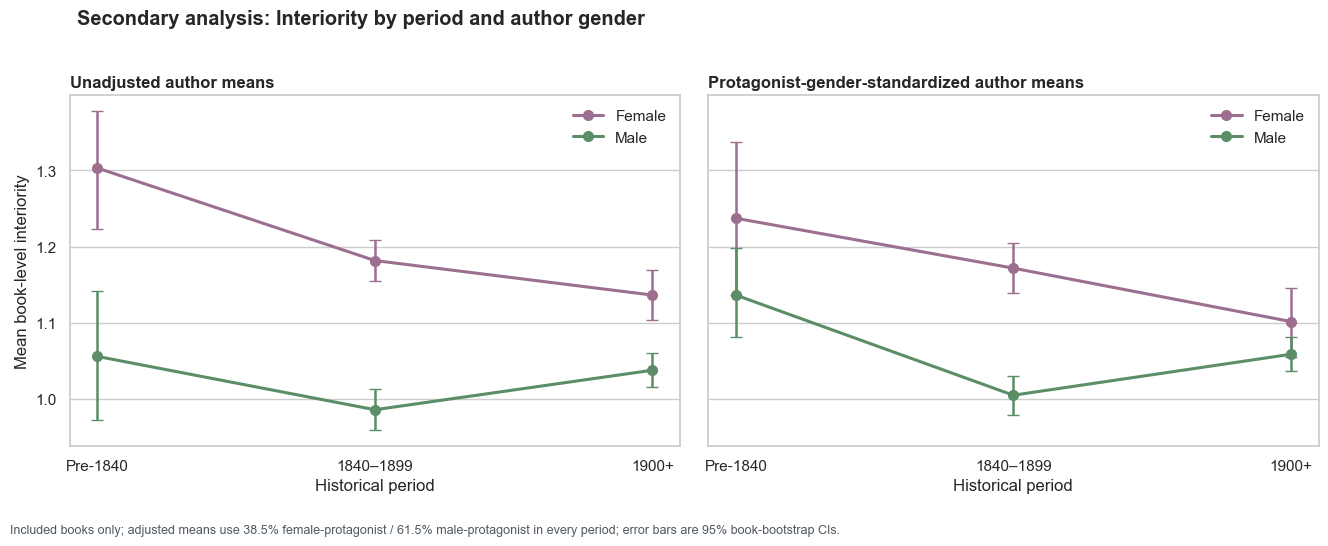

In [29]:
PROTAGONIST_STANDARDIZATION_WEIGHTS = (
    author_protagonist_data["protagonist_gender"]
    .value_counts(normalize=True)
    .reindex(AUTHOR_PROTAGONIST_LEVELS)
)
if PROTAGONIST_STANDARDIZATION_WEIGHTS.isna().any():
    raise ValueError("Protagonist-gender standardization requires both F and M protagonist strata.")

author_protagonist_count_rows = []
for period in TIME_PERIOD_ORDER:
    for author_gender in AUTHOR_LEVELS:
        for protagonist_gender in AUTHOR_PROTAGONIST_LEVELS:
            n_books = len(author_protagonist_values[(protagonist_gender, period, author_gender)])
            author_protagonist_count_rows.append({
                "period": PERIOD_LABELS[period],
                "author_gender": AUTHOR_LABELS[author_gender],
                "protagonist_gender": PROTAGONIST_LABELS[protagonist_gender],
                "n_books": n_books,
                "pooled_standardization_weight": PROTAGONIST_STANDARDIZATION_WEIGHTS.loc[protagonist_gender],
                "analysis_filter": "protagonist_analysis_status == included",
            })
author_protagonist_counts = pd.DataFrame(author_protagonist_count_rows)
author_protagonist_counts.to_csv(
    TABLE_DIR / "secondary_author_gender_protagonist_standardization_counts.csv", index=False
)
display(Markdown("##### Counts by period × author gender × protagonist gender"))
display(author_protagonist_counts.round({"pooled_standardization_weight": 4}))
display(Markdown(
    f"**Fixed protagonist-gender target:** {PROTAGONIST_STANDARDIZATION_WEIGHTS.loc['F']:.1%} female-protagonist / "
    f"{PROTAGONIST_STANDARDIZATION_WEIGHTS.loc['M']:.1%} male-protagonist in every period and author-gender group."
))

author_included_unadjusted_rng = np.random.default_rng(np.random.SeedSequence([BOOTSTRAP_SEED, 406]))
author_included_unadjusted_values = {}
author_included_unadjusted_draws = {}
author_protagonist_standardized_means = {}
author_protagonist_standardized_draws = {}
author_protagonist_standardization_mean_rows = []
for period in TIME_PERIOD_ORDER:
    for author_gender in AUTHOR_LEVELS:
        unadjusted_values = author_protagonist_data.loc[
            author_protagonist_data["time_period"].eq(period)
            & author_protagonist_data["author_gender"].eq(author_gender),
            "avg_interiority_score",
        ].to_numpy(float)
        unadjusted_draws = bootstrap_mean_draws(unadjusted_values, author_included_unadjusted_rng)
        author_included_unadjusted_values[(period, author_gender)] = unadjusted_values
        author_included_unadjusted_draws[(period, author_gender)] = unadjusted_draws

        adjusted_mean = 0.0
        adjusted_draws = np.zeros(BOOTSTRAP_REPETITIONS)
        component_counts = {}
        for protagonist_gender in AUTHOR_PROTAGONIST_LEVELS:
            values = author_protagonist_values[(protagonist_gender, period, author_gender)]
            draws = author_protagonist_draws[(protagonist_gender, period, author_gender)]
            weight = PROTAGONIST_STANDARDIZATION_WEIGHTS.loc[protagonist_gender]
            adjusted_mean += weight * values.mean()
            adjusted_draws += weight * draws
            component_counts[protagonist_gender] = len(values)
        author_protagonist_standardized_means[(period, author_gender)] = adjusted_mean
        author_protagonist_standardized_draws[(period, author_gender)] = adjusted_draws

        unadjusted_lower, unadjusted_upper = percentile_interval(unadjusted_draws)
        adjusted_lower, adjusted_upper = percentile_interval(adjusted_draws)
        author_protagonist_standardization_mean_rows.extend([
            {
                "estimate_type": "unadjusted_group_mean",
                "period": PERIOD_LABELS[period],
                "author_gender": AUTHOR_LABELS[author_gender],
                "estimate": unadjusted_values.mean(),
                "ci_lower": unadjusted_lower,
                "ci_upper": unadjusted_upper,
                "n_books": len(unadjusted_values),
                "n_female_protagonist": component_counts["F"],
                "n_male_protagonist": component_counts["M"],
                "adjustment": "None; protagonist_analysis_status == included",
            },
            {
                "estimate_type": "protagonist_gender_standardized_mean",
                "period": PERIOD_LABELS[period],
                "author_gender": AUTHOR_LABELS[author_gender],
                "estimate": adjusted_mean,
                "ci_lower": adjusted_lower,
                "ci_upper": adjusted_upper,
                "n_books": len(unadjusted_values),
                "n_female_protagonist": component_counts["F"],
                "n_male_protagonist": component_counts["M"],
                "adjustment": f"Fixed mix: female protagonist={PROTAGONIST_STANDARDIZATION_WEIGHTS.loc['F']:.3f}; male protagonist={PROTAGONIST_STANDARDIZATION_WEIGHTS.loc['M']:.3f}",
            },
        ])

author_protagonist_standardization_period_means = pd.DataFrame(author_protagonist_standardization_mean_rows)
author_protagonist_standardization_period_means.to_csv(
    TABLE_DIR / "secondary_author_gender_protagonist_standardized_period_means.csv", index=False
)

x = np.arange(len(TIME_PERIOD_ORDER))
fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.4), sharex=True, sharey=True)
for author_gender, color in [("female", "#9C6F91"), ("male", "#5B8E67")]:
    unadjusted_estimates = np.array([
        author_included_unadjusted_values[(period, author_gender)].mean()
        for period in TIME_PERIOD_ORDER
    ])
    unadjusted_intervals = np.array([
        percentile_interval(author_included_unadjusted_draws[(period, author_gender)])
        for period in TIME_PERIOD_ORDER
    ])
    axes[0].plot(
        x, unadjusted_estimates, marker="o", linewidth=2.2, markersize=7,
        color=color, label=AUTHOR_LABELS[author_gender], zorder=3,
    )
    axes[0].errorbar(
        x, unadjusted_estimates,
        yerr=np.vstack([unadjusted_estimates - unadjusted_intervals[:, 0], unadjusted_intervals[:, 1] - unadjusted_estimates]),
        fmt="none", ecolor=color, elinewidth=1.8, capsize=4, zorder=2,
    )

    adjusted_estimates = np.array([
        author_protagonist_standardized_means[(period, author_gender)]
        for period in TIME_PERIOD_ORDER
    ])
    adjusted_intervals = np.array([
        percentile_interval(author_protagonist_standardized_draws[(period, author_gender)])
        for period in TIME_PERIOD_ORDER
    ])
    axes[1].plot(
        x, adjusted_estimates, marker="o", linewidth=2.2, markersize=7,
        color=color, label=AUTHOR_LABELS[author_gender], zorder=3,
    )
    axes[1].errorbar(
        x, adjusted_estimates,
        yerr=np.vstack([adjusted_estimates - adjusted_intervals[:, 0], adjusted_intervals[:, 1] - adjusted_estimates]),
        fmt="none", ecolor=color, elinewidth=1.8, capsize=4, zorder=2,
    )

for ax, title in zip(axes, ["Unadjusted author means", "Protagonist-gender-standardized author means"]):
    ax.set_xticks(x, PUBLICATION_PERIODS)
    ax.set_xlabel("Historical period")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.legend(frameon=False)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Mean book-level interiority")
fig.suptitle("Secondary analysis: Interiority by period and author gender", x=0.06, ha="left", fontweight="bold")
fig.text(
    0.01, 0.01,
    f"Included books only; adjusted means use {PROTAGONIST_STANDARDIZATION_WEIGHTS.loc['F']:.1%} female-protagonist / {PROTAGONIST_STANDARDIZATION_WEIGHTS.loc['M']:.1%} male-protagonist in every period; error bars are 95% book-bootstrap CIs.",
    fontsize=9, color="#4F5963",
)
fig.tight_layout(rect=[0, 0.05, 1, 0.96])
save_figure(fig, FIGURE_DIR, "secondary_author_gender_protagonist_standardized_period_means")
plt.show()


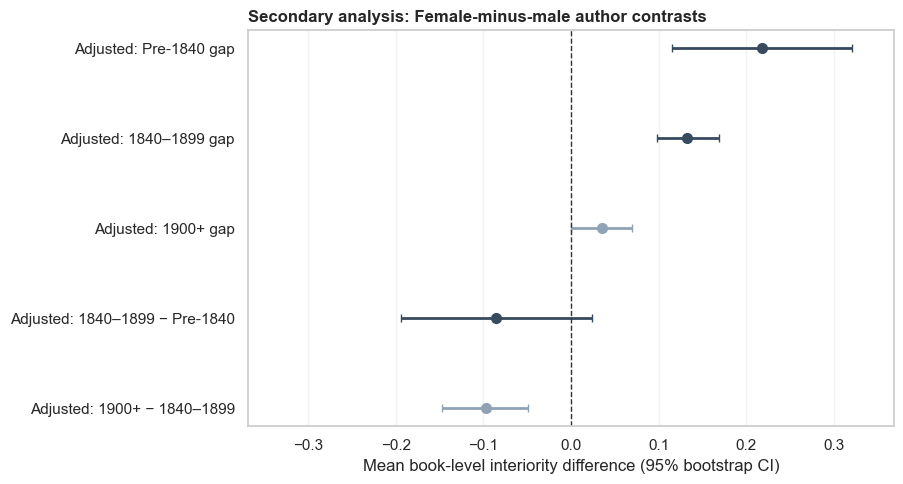

In [30]:
author_forest_labels = [
    "Adjusted: Pre-1840 gap", "Adjusted: 1840–1899 gap", "Adjusted: 1900+ gap",
    "Adjusted: 1840–1899 − Pre-1840", "Adjusted: 1900+ − 1840–1899",
]
forest_plot(
    author_effects,
    author_forest_labels,
    "Secondary analysis: Female-minus-male author contrasts",
    "Mean book-level interiority difference (95% bootstrap CI)",
    "secondary_author_gender_contrasts_forest",
)


In [31]:
author_primary_change = author_effects.loc[
    author_effects["estimate_type"].eq("historical_change")
].iloc[0]
author_extension = author_effects.loc[
    author_effects["estimate_type"].eq("historical_change")
].iloc[1]
display(Markdown(
    "### Secondary author-gender summary\n\n"
    f"At the fixed pooled genre composition, the 1840–1899 minus Pre-1840 author-gap change was "
    f"{author_primary_change['estimate']:.3f} (95% CI {author_primary_change['ci_lower']:.3f} to "
    f"{author_primary_change['ci_upper']:.3f}; {interval_position(author_primary_change['ci_lower'], author_primary_change['ci_upper'])}). "
    f"The twentieth-century extension was {author_extension['estimate']:.3f} "
    f"(95% CI {author_extension['ci_lower']:.3f} to {author_extension['ci_upper']:.3f}). "
    "These estimates are secondary and do not determine the primary H2 conclusion."
))


### Secondary author-gender summary

At the fixed pooled genre composition, the 1840–1899 minus Pre-1840 author-gap change was -0.085 (95% CI -0.194 to 0.024; spans zero). The twentieth-century extension was -0.097 (95% CI -0.147 to -0.049). These estimates are secondary and do not determine the primary H2 conclusion.

## Combined tidy confirmatory results

`group_mean` rows describe period/group means. `adjusted_group_mean` rows describe means standardized to the fixed genre composition. `direct_contrast` and `historical_change` rows answer the corresponding primary or secondary contrast. The `analysis_component` field distinguishes the primary protagonist analysis from the author-gender extension.


In [32]:
h2_mean_rows = []
for period in TIME_PERIOD_ORDER:
    for gender in ["F", "M"]:
        values = h2_protagonist_values[(period, gender)]
        lower, upper = percentile_interval(h2_protagonist_draws[(period, gender)])
        h2_mean_rows.append({
            "hypothesis": "H2", "analysis_component": "primary_protagonist_unadjusted",
            "estimate_type": "group_mean", "period_or_contrast": PERIOD_LABELS[period],
            "group": f"Protagonist: {PROTAGONIST_LABELS[gender]}", "estimate": values.mean(),
            "ci_lower": lower, "ci_upper": upper, "n_books": len(values),
            "n_female": len(values) if gender == "F" else np.nan,
            "n_male": len(values) if gender == "M" else np.nan, "n_mixed": np.nan,
            "book_counts": f"{PROTAGONIST_LABELS[gender].lower()}={len(values)}",
            "adjustment": "None; within-period equal-book mean",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        })
        adjusted_draws = h2_protagonist_adjusted_draws[(period, gender)]
        adj_lower, adj_upper = percentile_interval(adjusted_draws)
        h2_mean_rows.append({
            "hypothesis": "H2", "analysis_component": "primary_protagonist_domestic_standardized",
            "estimate_type": "adjusted_group_mean", "period_or_contrast": PERIOD_LABELS[period],
            "group": f"Protagonist: {PROTAGONIST_LABELS[gender]}",
            "estimate": h2_protagonist_adjusted_means[(period, gender)],
            "ci_lower": adj_lower, "ci_upper": adj_upper, "n_books": len(values),
            "n_female": len(values) if gender == "F" else np.nan,
            "n_male": len(values) if gender == "M" else np.nan, "n_mixed": np.nan,
            "book_counts": f"{PROTAGONIST_LABELS[gender].lower()}={len(values)}",
            "adjustment": f"Fixed mix: non-domestic={GENDER_STANDARDIZATION_WEIGHTS.loc[0]:.3f}; domestic={GENDER_STANDARDIZATION_WEIGHTS.loc[1]:.3f}",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        })

author_mean_rows = []
for period in TIME_PERIOD_ORDER:
    for gender in AUTHOR_LEVELS:
        values = author_unadjusted_values[(period, gender)]
        lower, upper = percentile_interval(author_unadjusted_draws[(period, gender)])
        author_mean_rows.append({
            "hypothesis": "H2", "analysis_component": "secondary_author_unadjusted",
            "estimate_type": "group_mean", "period_or_contrast": PERIOD_LABELS[period],
            "group": f"Author: {AUTHOR_LABELS[gender]}", "estimate": values.mean(),
            "ci_lower": lower, "ci_upper": upper, "n_books": len(values),
            "n_female": len(values) if gender == "female" else np.nan,
            "n_male": len(values) if gender == "male" else np.nan, "n_mixed": np.nan,
            "book_counts": f"{gender}={len(values)}", "adjustment": "None; within-period equal-book mean",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        })
        adj_draws = author_adjusted_draws[(period, gender)]
        adj_lower, adj_upper = percentile_interval(adj_draws)
        author_mean_rows.append({
            "hypothesis": "H2", "analysis_component": "secondary_author_domestic_standardized",
            "estimate_type": "adjusted_group_mean", "period_or_contrast": PERIOD_LABELS[period],
            "group": f"Author: {AUTHOR_LABELS[gender]}", "estimate": author_adjusted_means[(period, gender)],
            "ci_lower": adj_lower, "ci_upper": adj_upper, "n_books": len(values),
            "n_female": len(values) if gender == "female" else np.nan,
            "n_male": len(values) if gender == "male" else np.nan, "n_mixed": np.nan,
            "book_counts": f"{gender}={len(values)}",
            "adjustment": f"Fixed mix: non-domestic={GENDER_STANDARDIZATION_WEIGHTS.loc[0]:.3f}; domestic={GENDER_STANDARDIZATION_WEIGHTS.loc[1]:.3f}",
            "interpretation_scope": SCOPE_BY_PERIOD[period],
        })

results_tidy = pd.concat(
    [
        h1_period_means, h1_effects,
        pd.DataFrame(h2_mean_rows), h2_protagonist_effects, h2_protagonist_adjusted_effects,
        h3_quote_period_means, h3_quote_changes,
        pd.DataFrame(author_mean_rows), author_effects,
    ],
    ignore_index=True,
)[[
    "hypothesis", "analysis_component", "estimate_type", "period_or_contrast", "group",
    "estimate", "ci_lower", "ci_upper", "n_books",
    "n_domestic", "n_non_domestic", "n_female", "n_male", "n_mixed",
    "book_counts", "adjustment", "interpretation_scope",
]]

results_tidy.to_csv(TABLE_DIR / "confirmatory_results_tidy.csv", index=False)
h1_period_means.to_csv(TABLE_DIR / "h1_period_group_means.csv", index=False)
h1_effects.to_csv(TABLE_DIR / "h1_effects.csv", index=False)
pd.DataFrame(h2_mean_rows).to_csv(TABLE_DIR / "h2_protagonist_period_means.csv", index=False)
h2_protagonist_effects.to_csv(TABLE_DIR / "h2_protagonist_effects.csv", index=False)
h2_protagonist_adjusted_effects.to_csv(TABLE_DIR / "h2_protagonist_adjusted_effects.csv", index=False)
h3_quote_period_means.to_csv(TABLE_DIR / "h3_quote_period_means.csv", index=False)
h3_quote_changes.to_csv(TABLE_DIR / "h3_quote_historical_changes.csv", index=False)
pd.DataFrame(author_mean_rows).to_csv(TABLE_DIR / "secondary_author_period_means.csv", index=False)
author_effects.to_csv(TABLE_DIR / "secondary_author_effects.csv", index=False)
pd.DataFrame([
    {"scope": "All author-analysis books pooled across periods; fixed weights also used for adjusted H2", "is_domestic": status, "weight": weight}
    for status, weight in GENDER_STANDARDIZATION_WEIGHTS.items()
]).to_csv(TABLE_DIR / "gender_standardization_weights.csv", index=False)

display(results_tidy.round({"estimate": 4, "ci_lower": 4, "ci_upper": 4}))
print(f"Saved tidy results: {TABLE_DIR / 'confirmatory_results_tidy.csv'}")
print(f"Saved figures and supporting tables under: {OUTPUT_DIR}")


,hypothesis,analysis_component,estimate_type,period_or_contrast,group,estimate,ci_lower,ci_upper,n_books,n_domestic,n_non_domestic,n_female,n_male,n_mixed,book_counts,adjustment,interpretation_scope
0,H1,NaN,group_mean,Pre-1840,Domestic,1.3105,1.2068,1.3948,19,19.0,NaN,NaN,NaN,NaN,domestic=19,NaN,primary
1,H1,NaN,group_mean,Pre-1840,Non-domestic,1.1283,1.0657,1.1894,90,NaN,90.0,NaN,NaN,NaN,non-domestic=90,NaN,primary
2,H1,NaN,group_mean,1840–1899,Domestic,1.1728,1.1506,1.1952,190,190.0,NaN,NaN,NaN,NaN,domestic=190,NaN,primary
3,H1,NaN,group_mean,1840–1899,Non-domestic,1.0120,0.9893,1.0336,366,NaN,366.0,NaN,NaN,NaN,non-domestic=366,NaN,primary
4,H1,NaN,group_mean,1900+,Domestic,1.1950,1.1743,1.2158,258,258.0,NaN,NaN,NaN,NaN,domestic=258,NaN,extension
5,H1,NaN,group_mean,1900+,Non-domestic,0.9981,0.9793,1.0170,425,NaN,425.0,NaN,NaN,NaN,non-domestic=425,NaN,extension
6,H1,NaN,direct_contrast,Pre-1840: domestic − non-domestic,Domestic − non-domestic,0.1822,0.0621,0.2920,109,19.0,90.0,NaN,NaN,NaN,domestic=19; non-domestic=90,NaN,primary
7,H1,NaN,direct_contrast,1840–1899: domestic − non-domestic,Domestic − non-domestic,0.1609,0.1300,0.1915,556,190.0,366.0,NaN,NaN,NaN,domestic=190; non-domestic=366,NaN,primary
8,H1,NaN,direct_contrast,1900+: domestic − non-domestic,Domestic − non-domestic,0.1969,0.1691,0.2243,683,258.0,425.0,NaN,NaN,NaN,domestic=258; non-domestic=425,NaN,extension
9,H1,NaN,historical_change,1840–1899 gap − Pre-1840 gap,Change in domestic − non-domestic gap,-0.0213,-0.1334,0.0981,665,209.0,456.0,NaN,NaN,NaN,"Pre-1840: D=19, ND=90; 1840–1899: D=190, ND=366",NaN,primary


Saved tidy results: /Users/chelseachen/Desktop/interiority/confirmatory_hypothesis_analysis_outputs/tables/confirmatory_results_tidy.csv
Saved figures and supporting tables under: /Users/chelseachen/Desktop/interiority/confirmatory_hypothesis_analysis_outputs


## Revised notebook map

The primary hypotheses now appear in the requested order: **H1 domestic status**, **H2 protagonist gender**, and **H3 quoted versus non-quoted interiority within domestic fiction**. Author gender follows as a clearly separated secondary extension of H2.

Two figures were added before the H1 contrast table: period-level domestic/non-domestic means with 95% book-bootstrap CIs, and period-specific domestic-minus-non-domestic contrasts with a zero reference line. Protagonist and author figures are no longer combined, and each analysis retains its own means figure and forest plot.
